# Training-size stability of the current completion policy trees

Uses the old SA07 fraction/seed grid with the current residential and outpatient **service-setting** treatment contrasts. Original tree-build and held-out episodes stay fixed. The alternative forest and tree are refit on each training subsample. One timestamped folder contains all 32 fits and a `progress.csv` checkpoint. To resume, set `REPLICATION_SA07_RESUME_DIR` to that folder.

In [1]:
from pathlib import Path
from datetime import datetime
import gc, hashlib, json, os, platform, sys, time
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import joblib
from scipy.stats import t as student_t
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from econml.dml import CausalForestDML
from econml.policy import PolicyTree
from IPython.display import display
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'configs/stage1_specifications.json').is_file())
HOME=ROOT/'S1'
FIXED_OUTPUTS=Path(os.environ.get('REPLICATION_S1_FIXED_OUTPUTS',ROOT/'S1/fixed_inputs')).resolve()
sys.path.insert(0,str(HOME/'helper'))
from reporting import Review
SPEC=json.loads((HOME/'helper/assets/sample_specification.json').read_text())
X_FIELDS=[x for x in SPEC['fields'] if x not in ('STFIPS','DISYR')]
OUTPUTS=ROOT/'S1/sensitivity/outputs';REPORTS=ROOT/'S1/sensitivity/reports'
OUTPUTS.mkdir(parents=True,exist_ok=True);REPORTS.mkdir(parents=True,exist_ok=True)
def sha(path):
    with Path(path).open('rb') as f:return hashlib.file_digest(f,'sha256').hexdigest()
COMPLETE_STATUSES={
 'S1_01_data_preparation':{'verified_samples_and_imputation_draws'},
 'S1_02_outcome_review':{'descriptive_review_complete_inference_pending'},
 'S1_03_outpatient_data_preparation':{'candidate_membership_and_four_imputation_draws_verified','candidate_membership_and_four_imputation_draws_verified_overlap_review_required'},
 'S1_04_outpatient_outcome_review':{'descriptive_review_complete_readiness_issues_identified'},
}
def newest(prefix):
    for p in sorted(FIXED_OUTPUTS.glob(prefix+'_*'),reverse=True):
        manifest=p/'manifest.json'
        if manifest.is_file():
            m=json.loads(manifest.read_text())
            if m.get('status') in COMPLETE_STATUSES[prefix]:return p,m
    raise FileNotFoundError(f'No complete {prefix} run under fixed input folder: {FIXED_OUTPUTS}')
res,m_res=newest('S1_01_data_preparation')
res_review,m_rr=newest('S1_02_outcome_review')
out,m_out=newest('S1_03_outpatient_data_preparation')
out_review,m_or=newest('S1_04_outpatient_outcome_review')
assert m_res['status']=='verified_samples_and_imputation_draws'
assert m_rr['status']=='descriptive_review_complete_inference_pending'
assert m_out['status'] in {'candidate_membership_and_four_imputation_draws_verified','candidate_membership_and_four_imputation_draws_verified_overlap_review_required'}
assert m_out['analysis_role']=='primary_14_state' and len(m_out['states'])==14
assert m_or['status']=='descriptive_review_complete_readiness_issues_identified'
for review,manifest,source in [(res_review,m_rr,res),(out_review,m_or,out)]:
    assert manifest['source_run']==source.name
    assert manifest['source_manifest_sha256']==sha(source/'manifest.json')
assert m_or['output_sha256']==sha(out_review/m_or['output_file'])
assert all(sha(res/name)==meta['sha256'] for name,meta in m_res['outputs'].items())
assert all(sha(out/item['file'])==item['sha256'] for item in m_out['imputation']['draws'])
BRANCHES={
 'residential':{'source':res,'treatment_0':'short-term residential','treatment_1':'long-term residential',
                'eligible_file':res/'completion_final_eligible.csv.gz',
                'complete_case_file':res/'completion_final_complete_case.csv.gz',
                'eligible_n':m_res['outputs']['completion_final_eligible.csv.gz']['n'],
                'complete_case_n':m_res['outputs']['completion_final_complete_case.csv.gz']['n']},
 'outpatient':{'source':out,'treatment_0':'non-intensive outpatient','treatment_1':'intensive outpatient',
               'eligible_file':out/'completion_final_eligible.csv.gz',
               'complete_case_file':out/'completion_final_eligible.csv.gz',
               'eligible_n':next(x['n'] for x in m_out['samples'] if x['outcome']=='completion'),
               'complete_case_n':next(x['complete_case_n'] for x in m_out['samples'] if x['outcome']=='completion')},
}
print('Fixed Stage 1 inputs:',FIXED_OUTPUTS)
print('New policy-tree outputs:',OUTPUTS)
for branch,info in BRANCHES.items():
    assert info['eligible_file'].is_file() and info['complete_case_file'].is_file()
    print(branch,info['source'].name,'eligible',info['eligible_n'],'complete-case',info['complete_case_n'])
RUN=Path(os.environ.get('REPLICATION_SA07_RESUME_DIR',OUTPUTS/f'S1_sample_size_stability_{datetime.now().astimezone():%Y%m%d_%H%M%S_%f}'))
RUN.mkdir(parents=True,exist_ok=True)
review=Review(REPORTS,'S1_sample_size_stability')
review.note('Exploratory training-size stability of current primary eligible residential and outpatient completion trees. Tree-build and held-out episodes remain fixed. Each subsample refits nuisance models and the causal forest. This is not an inferential sensitivity interval.')

Fixed Stage 1 inputs: /Users/researcher/code_projects/Causal Discovery /code/project_code/notebooks/S1/outputs
New policy-tree outputs: /Users/researcher/code_projects/Causal Discovery /S1/sensitivity/outputs
residential S1_01_data_preparation_20260922_113427_904266 eligible 241118 complete-case 208421
outpatient S1_03_outpatient_data_preparation_20260922_130720_144842 eligible 386282 complete-case 244730


In [2]:
def dr_rewards(y,t,e,m0,m1):
    y=np.asarray(y,float);t=np.asarray(t,int);e=np.asarray(e,float)
    assert len(y)==len(t)==len(e)==len(m0)==len(m1)>0
    assert np.isin(y,[0,1]).all() and np.isin(t,[0,1]).all()
    assert np.isfinite(e).all() and ((e>0)&(e<1)).all()
    return np.column_stack((m0+(t==0)*(y-m0)/(1-e),m1+(t==1)*(y-m1)/e))
def policy_values(rewards,e,action,state):
    h=e*(1-e);state=np.asarray(state)
    policies={'tree':np.asarray(action,int),'always_0':np.zeros(len(action),int),'always_1':np.ones(len(action),int)}
    rows=[];chosen={}
    for name,a in policies.items():
        score=rewards[np.arange(len(a)),a]
        chosen[name]=score
        rows.append({'policy':name,'n':len(a),'overlap_value':np.average(score,weights=h),
                     'intensive_or_long_share':float(a.mean()),'overlap_ess':float(h.sum()**2/(h@h))})
    sensitivity=[]
    for s in sorted(set(state)):
        keep=state!=s
        if keep.any():
            contrast=np.average((chosen['tree']-chosen['always_0'])[keep],weights=h[keep])
            sensitivity.append({'omitted_state':s,'tree_minus_always_0':contrast,'n':int(keep.sum())})
    return pd.DataFrame(rows),pd.DataFrame(sensitivity)


TREE_LABELS={
 'RACE_4.0':('race','Black or African American'),
 'additional_substances_total_0.0':('additional substances','no additional substances recorded'),
 'additional_substances_total_nan':('additional substances','number of additional substances missing'),
 'ROUTE1_3.0':('primary route of administration','inhalation'),
 'ROUTE1_1.0':('primary route of administration','oral'),
 'PSOURCE_1.0':('referral source','individual, including self-referral'),
 'PSOURCE_2.0':('referral source','alcohol or drug use care provider'),
 'EMPLOY_4.0':('employment status','not in the labor force'),
 'SUB1_2.0':('primary substance','alcohol'),
 'SUB1_10.0':('primary substance','methamphetamine or speed'),
 'SUB1_5.0':('primary substance','heroin'),
}
def alpha_label(position):
    label=''
    while position>=0:
        position,remainder=divmod(position,26);label=chr(65+remainder)+label;position-=1
    return label
def node_letters(model):
    queue=[0];labels={}
    while queue:
        node=queue.pop(0);labels[node]=alpha_label(len(labels))
        left,right=int(model.children_left[node]),int(model.children_right[node])
        if left>=0:queue.extend([left,right])
    assert labels[0]=='A' and len(labels)==model.node_count and len(set(labels.values()))==model.node_count
    return labels
def node_effects(tree,policy_x,rewards,e,state):
    membership=tree.tree_model_.decision_path(policy_x).tocsc();delta=rewards[:,1]-rewards[:,0];h=e*(1-e);rows=[]
    for node in range(tree.tree_model_.tree_.node_count):
        keep=membership[:,node].toarray().ravel().astype(bool);w=h[keep]
        rows.append({'node':node,'n':int(keep.sum()),'state_clusters':int(np.unique(np.asarray(state)[keep]).size),'effect':float(np.average(delta[keep],weights=w))})
    return pd.DataFrame(rows)

def leaf_inference(tree,policy_x,rewards,e,state):
    """Held-out leaf effects with state-clustered, Holm-adjusted p-values."""
    leaf=tree.apply(policy_x);delta=rewards[:,1]-rewards[:,0];h=e*(1-e)
    rows=[]
    for node in sorted(np.unique(leaf)):
        keep=leaf==node;w=h[keep];z=delta[keep];g=np.asarray(state)[keep]
        effect=float(np.average(z,weights=w));total=float(w.sum())
        scores=pd.Series(w*(z-effect),index=g).groupby(level=0).sum().to_numpy()/total
        clusters=len(scores)
        se=float(np.sqrt(clusters/(clusters-1)*np.square(scores).sum())) if clusters>1 else np.nan
        p=float(2*student_t.sf(abs(effect/se),df=clusters-1)) if np.isfinite(se) and se>0 else np.nan
        rows.append({'node':int(node),'n':int(keep.sum()),'state_clusters':clusters,
                     'effect':effect,'state_clustered_se':se,'p_raw':p})
    out=pd.DataFrame(rows)
    valid=out.p_raw.notna();m=int(valid.sum())
    if m:
        idx=out.index[valid].to_numpy();order=idx[np.argsort(out.loc[idx,'p_raw'].to_numpy())]
        adjusted=np.maximum.accumulate((m-np.arange(m))*out.loc[order,'p_raw'].to_numpy())
        out.loc[order,'p_holm']=np.minimum(adjusted,1)
    else:out['p_holm']=np.nan
    return out

def significance_stars(p):
    if not np.isfinite(p):return ''
    return '***' if p<.01 else '**' if p<.05 else '*' if p<.10 else ''
# Small executable check of both action scores and the overlap-policy comparison.
y=np.array([0,1,0,1]);t=np.array([0,1,0,1]);e=np.full(4,.5)
r=dr_rewards(y,t,e,np.array([0,.5,0,.5]),np.array([.5,1,.5,1]))
assert np.allclose(r[:,0],[0,.5,0,.5]) and np.allclose(r[:,1],[.5,1,.5,1])
assert [alpha_label(x) for x in (0,25,26)]==['A','Z','AA']
v,_=policy_values(r,e,np.ones(4,int),np.array([1,1,2,2]))
assert np.isclose(v.set_index('policy').loc['tree','overlap_value']-v.set_index('policy').loc['always_0','overlap_value'],.5)
print('Doubly robust score and policy-value self-check passed')

def prepare_sample(branch,info,scope):
    assert scope in ('eligible','complete_case')
    path=info['file']
    if branch=='residential':
        assert sha(path)==m_res['outputs'][path.name]['sha256']
        d=pd.read_csv(path)
        assert len(d)==info['expected_n']
    else:
        d=pd.read_csv(path)
        expected=next(x for x in m_out['samples'] if x['outcome']=='completion')
        assert len(d)==expected['n'] and d.episode_source_id.is_unique
        ids=d.episode_source_id.astype(str)
        digest=hashlib.sha256(('\n'.join(sorted(ids))+'\n').encode()).hexdigest()
        assert digest==expected['membership_sha256']
        if scope=='complete_case':d=d.loc[d.complete_case.eq(1)].reset_index(drop=True)
        assert len(d)==info['expected_n']
    assert d.episode_source_id.is_unique
    assert d.treatment.isin([0,1]).all() and d.outcome.isin([0,1]).all()
    assert d[['STFIPS','DISYR']].notna().all().all()
    if scope=='complete_case':assert d[X_FIELDS].notna().all().all()
    return d

def split_positions(d):
    groups=d.STFIPS.astype(str)+'_'+d.DISYR.astype(str)+'_'+d.treatment.astype(int).astype(str)
    assert groups.value_counts().min()>=10
    positions=np.arange(len(d))
    train,remainder=train_test_split(positions,test_size=.4,random_state=42,stratify=groups)
    build,test=train_test_split(remainder,test_size=.5,random_state=43,stratify=groups.iloc[remainder])
    assert len(set(train)&set(build))==len(set(train)&set(test))==len(set(build)&set(test))==0
    assert len(train)+len(build)+len(test)==len(d)
    return {'train':np.sort(train),'build':np.sort(build),'test':np.sort(test)}

def encode(d,roles,temporal=False):
    train=roles['train']
    x_encoder=OneHotEncoder(handle_unknown='ignore',sparse_output=False,dtype=np.float32)
    w_encoder=OneHotEncoder(handle_unknown='ignore',sparse_output=False,dtype=np.float32)
    x_encoder.fit(d.iloc[train][X_FIELDS].astype(str))
    adjustment=d[['STFIPS']].astype(str) if temporal else (d.STFIPS.astype(str)+'_'+d.DISYR.astype(str)).to_frame('state_year')
    w_encoder.fit(adjustment.iloc[train])
    X={k:x_encoder.transform(d.iloc[v][X_FIELDS].astype(str)) for k,v in roles.items()}
    W={k:w_encoder.transform(adjustment.iloc[v]) for k,v in roles.items()}
    assert X['train'].shape[1]>0 and W['train'].shape[1]>0
    return x_encoder,w_encoder,X,W

def fit_branch(branch,info,d,roles,scope,temporal=False,policy_mode_impute=False):
    started=time.perf_counter();dest=RUN/branch;dest.mkdir()
    xenc,wenc,X,W=encode(d,roles,temporal)
    train,build,test=[roles[k] for k in ('train','build','test')]
    T=d.treatment.to_numpy(int)
    if policy_mode_impute:
        modes=d.iloc[train][X_FIELDS].mode(dropna=True).iloc[0]
        assert modes.notna().all()
        policy_frame=d[X_FIELDS].fillna(modes.to_dict()).astype(str)
        policy_encoder=OneHotEncoder(handle_unknown='ignore',sparse_output=False,dtype=np.float32).fit(policy_frame.iloc[train])
        P={k:policy_encoder.transform(policy_frame.iloc[v]) for k,v in roles.items()}
        feature_names=list(policy_encoder.get_feature_names_out(X_FIELDS))
        assert not any(name.endswith('_nan') for name in feature_names)
    else:
        modes=None;policy_encoder=xenc;P=X
        feature_names=list(xenc.get_feature_names_out(X_FIELDS))
    def full(k):return np.hstack((X[k],W[k]))
    a=full('train');t=T[train];y=d.outcome.iloc[train].to_numpy(int)
    propensity=LogisticRegression(C=1,max_iter=2000,solver='lbfgs').fit(a,t)
    mu0=RandomForestRegressor(n_estimators=50,max_depth=5,min_samples_leaf=20,n_jobs=2,random_state=51).fit(a[t==0],y[t==0])
    mu1=RandomForestRegressor(n_estimators=50,max_depth=5,min_samples_leaf=20,n_jobs=2,random_state=52).fit(a[t==1],y[t==1])
    forest=CausalForestDML(model_y=RandomForestRegressor(n_estimators=50,max_depth=5,min_samples_leaf=20,n_jobs=2,random_state=53),
                           model_t=RandomForestClassifier(n_estimators=50,max_depth=5,min_samples_leaf=20,n_jobs=2,random_state=54),
                           n_estimators=200,min_samples_leaf=40,honest=True,discrete_treatment=True,cv=5,
                           random_state=55,n_jobs=2)
    forest.fit(y,t,X=X['train'],W=W['train'],inference=None)
    build_e=propensity.predict_proba(full('build'))[:,1]
    build_m0=mu0.predict(full('build'));build_m1=mu1.predict(full('build'))
    rewards=dr_rewards(d.outcome.iloc[build].to_numpy(int),T[build],build_e,build_m0,build_m1)
    weight=build_e*(1-build_e)
    min_leaf=max(500,int(.01*len(build)))
    tree=PolicyTree(max_depth=3,min_samples_leaf=min_leaf,honest=True,random_state=56)
    tree.fit(P['build'],rewards,sample_weight=weight)
    # Treatment and admission data from 2023 define the 2023 overlap target; no 2023 outcome is used here.
    eval_propensity=LogisticRegression(C=1,max_iter=2000,solver='lbfgs').fit(full('test'),T[test]) if temporal else propensity
    frozen=dest/'frozen_policy.joblib'
    joblib.dump({'tree':tree,'forest':forest,'x_encoder':xenc,'w_encoder':wenc,'propensity':propensity,'evaluation_propensity':eval_propensity,'policy_encoder':policy_encoder,'policy_modes':None if modes is None else modes.to_dict(),'mu0':mu0,'mu1':mu1,
                 'x_fields':X_FIELDS,'feature_names':feature_names},frozen,compress=3)
    frozen_sha=sha(frozen)
    # Outcome access for evaluation starts only after the rule and nuisance models are frozen.
    test_e=eval_propensity.predict_proba(full('test'))[:,1]
    test_m0=mu0.predict(full('test'));test_m1=mu1.predict(full('test'))
    action=tree.predict(P['test']).astype(int)
    cate=forest.effect(X['test']).reshape(-1)
    test_rewards=dr_rewards(d.outcome.iloc[test].to_numpy(int),T[test],test_e,test_m0,test_m1)
    value,loo=policy_values(test_rewards,test_e,action,d.STFIPS.to_numpy()[test])
    value.insert(0,'branch',branch)
    value.to_csv(dest/'holdout_policy_value.csv',index=False)
    loo.to_csv(dest/'leave_one_state_out.csv',index=False)
    gain=test_rewards[np.arange(len(test)),action]-test_rewards[:,0]
    h=test_e*(1-test_e)
    leaves=leaf_inference(tree,P['test'],test_rewards,test_e,d.STFIPS.to_numpy()[test])
    nodes=node_effects(tree,P['test'],test_rewards,test_e,d.STFIPS.to_numpy()[test]);letters=node_letters(tree.tree_model_.tree_)
    nodes.insert(1,'letter',nodes.node.map(letters));nodes.to_csv(dest/'heldout_node_effects.csv',index=False)
    fig,ax=plt.subplots(figsize=(20,6))
    display_names=[': '.join(TREE_LABELS.get(name,(name,''))).rstrip(': ') for name in feature_names]
    tree.plot(ax=ax,feature_names=display_names,treatment_names=[info['treatment_0'],info['treatment_1']],fontsize=10)
    node_boxes=[artist for artist in ax.texts if artist.get_bbox_patch() is not None]
    assert len(node_boxes)==tree.tree_model_.tree_.node_count
    for node,artist in enumerate(node_boxes):
        lines=[line.replace('samples =','Build n =') for line in artist.get_text().splitlines()
               if not line.startswith('value =')]
        row=nodes.loc[nodes.node.eq(node)].iloc[0]
        artist.set_text(f'Node {letters[node]}\n'+'\n'.join(lines)+f'\nHeld-out n = {int(row.n):,}\nHeld-out effect: {100*row.effect:+.1f} pp')
    for row in leaves.itertuples(index=False):
        label=node_boxes[row.node].get_text()
        label=label.replace('Treatment = non-intensive outpatient','Recommend:\nnon-intensive outpatient')
        label=label.replace('Treatment = intensive outpatient','Recommend:\nintensive outpatient')
        label=label.replace('Treatment = short-term residential','Recommend:\nshort-term residential')
        label=label.replace('Treatment = long-term residential','Recommend:\nlong-term residential')
        label+=f'{significance_stars(row.p_holm)}'
        node_boxes[row.node].set_text(label)
    ax.set_title(f"{branch.replace('_',' ')} completion | {scope.replace('_',' ')} overlap policy tree (provisional)")
    fig.text(.5,.015,'Letters identify nodes breadth-first. Held-out effect is treatment 1 minus treatment 0; stars appear only on leaves and use state-clustered, Holm-adjusted p-values.',ha='center',fontsize=9)
    fig.savefig(dest/'policy_tree.png',dpi=150,bbox_inches='tight')
    display(fig)
    plt.close(fig)
    def grouped_gain(group):
        frame=pd.DataFrame({'group':np.asarray(group),'gain':gain,'weight':h,'action':action})
        return frame.groupby('group',dropna=False).apply(
            lambda z:pd.Series({'n':len(z),'weight_share':z.weight.sum()/h.sum(),
                                'tree_minus_always_0':np.average(z.gain,weights=z.weight),
                                'treatment_1_share':z.action.mean()}),include_groups=False).reset_index()
    grouped_gain(d.STFIPS.iloc[test]).to_csv(dest/'policy_gain_by_state.csv',index=False)
    grouped_gain(d.DISYR.iloc[test]).to_csv(dest/'policy_gain_by_year.csv',index=False)
    if scope=='eligible' and 'additional_substances_total' in d:
        grouped_gain(d.additional_substances_total.iloc[test].isna()).to_csv(dest/'policy_gain_by_additional_substances_missing.csv',index=False)
    omitted=loo.tree_minus_always_0.to_numpy()
    state_jackknife_se=float(np.sqrt((len(omitted)-1)/len(omitted)*np.square(omitted-omitted.mean()).sum()))
    calibration=pd.DataFrame({'quartile':pd.qcut(cate,4,labels=False,duplicates='drop'),
                              'cate':cate,'dr_effect':test_rewards[:,1]-test_rewards[:,0],
                              'overlap_weight':test_e*(1-test_e),'tree_treatment':action})
    calibration=calibration.groupby('quartile',dropna=False).apply(
        lambda z:pd.Series({'n':len(z),
                            'mean_predicted_cate':np.average(z.cate,weights=z.overlap_weight),
                            'heldout_dr_effect':np.average(z.dr_effect,weights=z.overlap_weight),
                            'tree_treatment_share':z.tree_treatment.mean()}),
        include_groups=False).reset_index()
    calibration.to_csv(dest/'cate_quartile_calibration.csv',index=False)
    assignments=pd.DataFrame({'episode_source_id':d.episode_source_id.iloc[test].to_numpy(),
        'DISYR':d.DISYR.iloc[test].to_numpy(),'STFIPS':d.STFIPS.iloc[test].to_numpy(),
        'policy':action,'cate':cate,'propensity':test_e})
    assignments.to_csv(dest/'holdout_assignments.csv.gz',index=False)
    policy_index=value.set_index('policy').overlap_value
    membership_hash=hashlib.sha256(('\n'.join(sorted(d.episode_source_id.astype(str)))+'\n').encode()).hexdigest()
    report={'branch':branch,'n_train':len(train),'n_build':len(build),'n_test':len(test),
            'states_in_test':int(d.STFIPS.iloc[test].nunique()),'sample_membership_sha256':membership_hash,'sample':scope,
            'evaluation_design':'2022_train_build_2023_test' if temporal else 'stratified_random_train_build_test',
            'evaluation_propensity':'fit_on_2023_treatment_and_admission_data' if temporal else 'fit_on_training_data',
            'policy_feature_representation':'training_mode_filled' if policy_mode_impute else 'literal_missing_category',
            'tree_minus_best_constant':float(policy_index['tree']-max(policy_index['always_0'],policy_index['always_1'])),
            'state_jackknife_se_tree_minus_always_0_descriptive':state_jackknife_se,
            'leaf_inference':leaves.where(pd.notna(leaves),None).to_dict(orient='records'),
            'node_inference':nodes.where(pd.notna(nodes),None).to_dict(orient='records'),
            'node_letter_order':'breadth_first, beginning with A at the root',
            'leaf_significance':'two-sided state-clustered t tests; Holm-adjusted across leaves; held-out evaluation sample',
            'forest_trees':200,'tree_depth':int(tree.get_depth()),
            'tree_leaves':int(tree.get_n_leaves()),'tree_min_leaf':min_leaf,'frozen_model_sha256':frozen_sha,
            'source_file':str(info['file'].relative_to(ROOT)),'source_file_sha256':sha(info['file']),
            'test_propensity_min':float(test_e.min()),'test_propensity_max':float(test_e.max()),
            'test_score_tail_percent':float(100*((test_e<.05)|(test_e>.95)).mean()),
            'elapsed_seconds':time.perf_counter()-started,
            'files':{p.name:sha(p) for p in dest.iterdir() if p.is_file()}}
    (dest/'manifest.json').write_text(json.dumps(report,indent=2)+'\n')
    print(branch,'n test',len(test),'tree leaves',tree.get_n_leaves(),'minutes',round(report['elapsed_seconds']/60,1))
    display(value)
    del forest,tree,mu0,mu1,propensity,X,W,P,d;gc.collect()
    return report,value

Doubly robust score and policy-value self-check passed


residential_train_025_seed_11 n test 48224 tree leaves 5 minutes 0.4
Saved stability fit 1 of 32 residential_train_025_seed_11
residential_train_025_seed_22 n test 48224 tree leaves 7 minutes 0.3
Saved stability fit 2 of 32 residential_train_025_seed_22
residential_train_025_seed_33 n test 48224 tree leaves 5 minutes 0.4
Saved stability fit 3 of 32 residential_train_025_seed_33
residential_train_025_seed_44 n test 48224 tree leaves 4 minutes 0.4
Saved stability fit 4 of 32 residential_train_025_seed_44
residential_train_025_seed_55 n test 48224 tree leaves 5 minutes 0.3
Saved stability fit 5 of 32 residential_train_025_seed_55
residential_train_050_seed_11 n test 48224 tree leaves 5 minutes 0.9
Saved stability fit 6 of 32 residential_train_050_seed_11
residential_train_050_seed_22 n test 48224 tree leaves 5 minutes 0.9
Saved stability fit 7 of 32 residential_train_050_seed_22
residential_train_050_seed_33 n test 48224 tree leaves 5 minutes 0.9
Saved stability fit 8 of 32 residential_tr

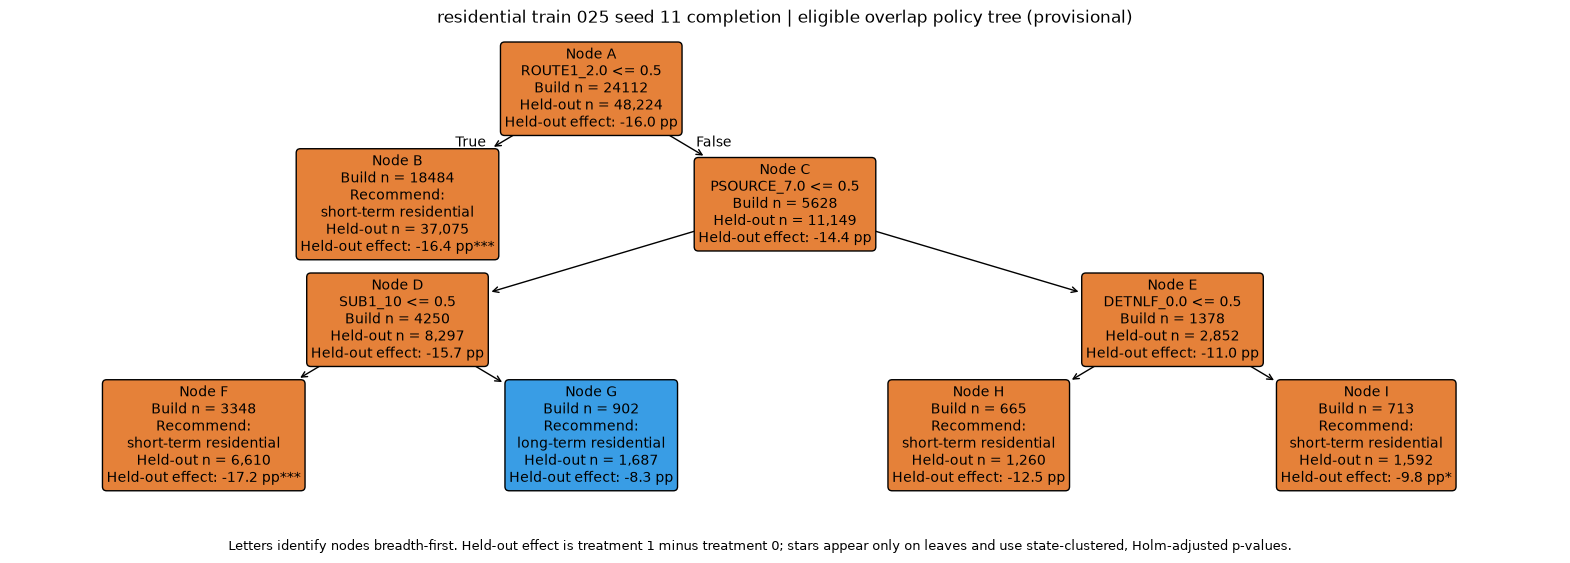

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,residential_train_025_seed_11,tree,48224,0.619568,0.034983,39524.667969
1,residential_train_025_seed_11,always_0,48224,0.621954,0.000000,39524.667969
2,residential_train_025_seed_11,always_1,48224,0.462413,1.000000,39524.667969


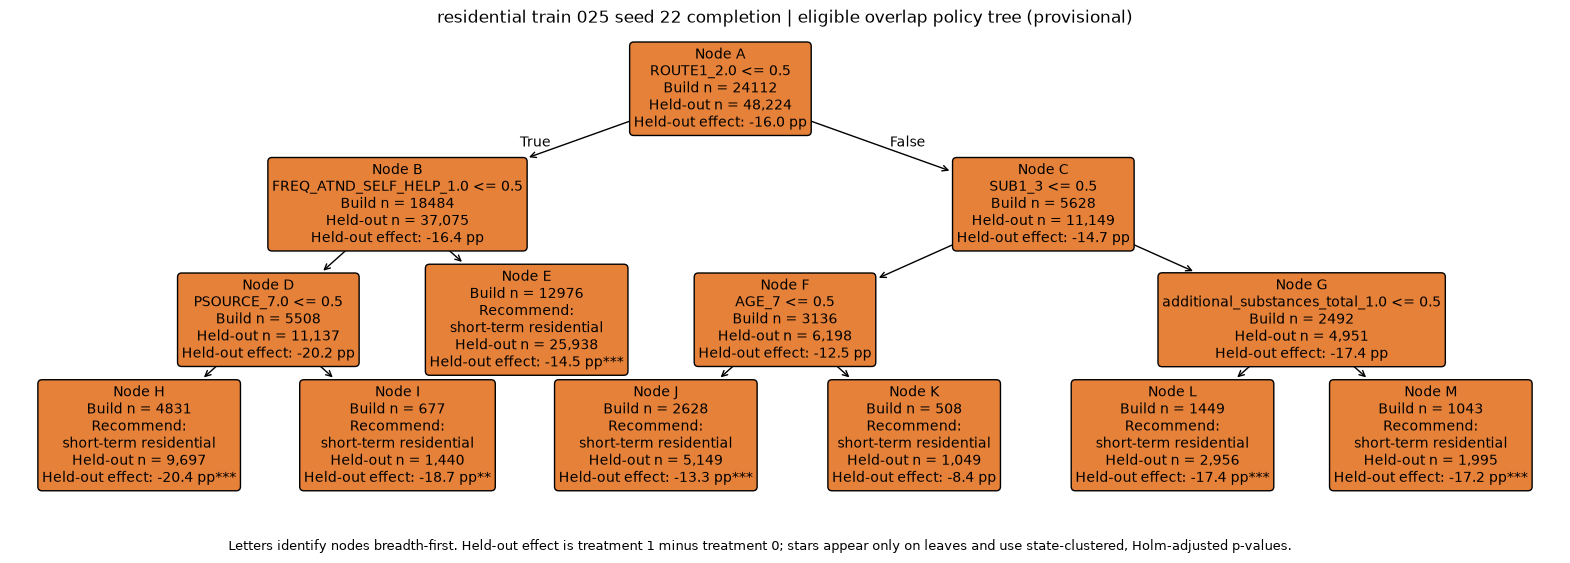

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,residential_train_025_seed_22,tree,48224,0.622527,0.0,39565.808594
1,residential_train_025_seed_22,always_0,48224,0.622527,0.0,39565.808594
2,residential_train_025_seed_22,always_1,48224,0.462218,1.0,39565.808594


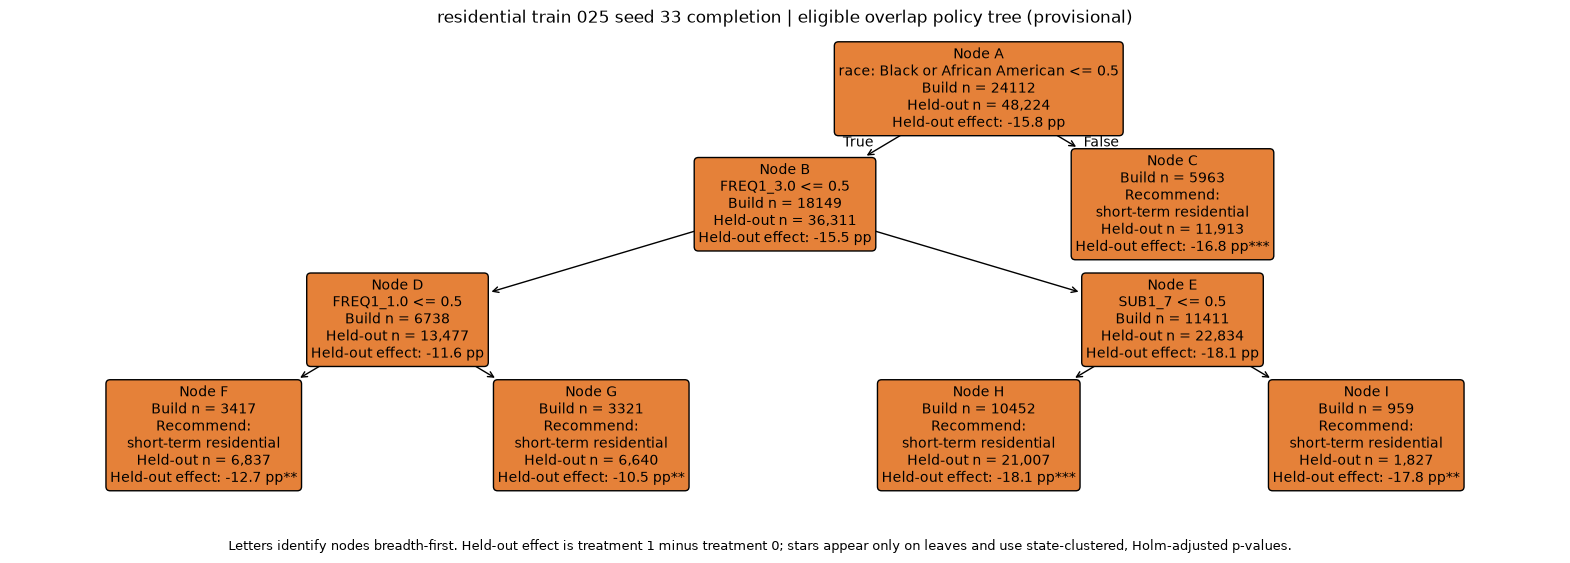

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,residential_train_025_seed_33,tree,48224,0.623074,0.0,39683.976562
1,residential_train_025_seed_33,always_0,48224,0.623074,0.0,39683.976562
2,residential_train_025_seed_33,always_1,48224,0.465177,1.0,39683.976562


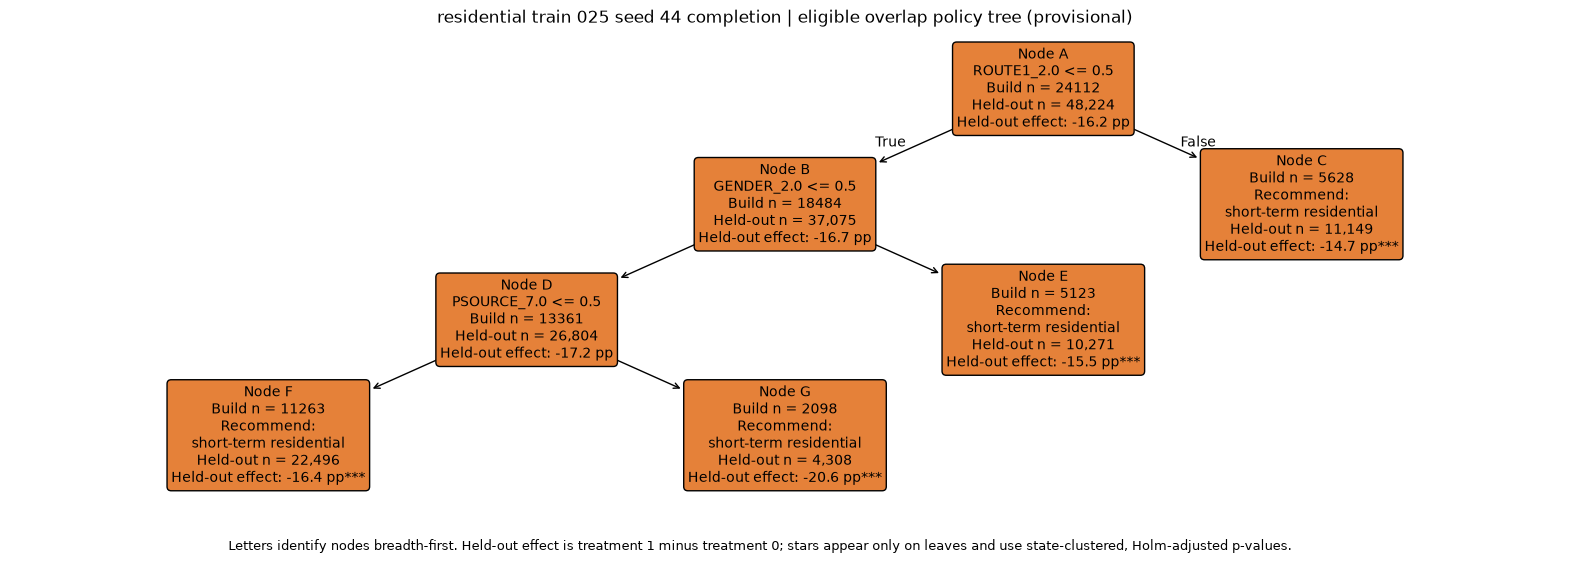

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,residential_train_025_seed_44,tree,48224,0.623682,0.0,39722.597656
1,residential_train_025_seed_44,always_0,48224,0.623682,0.0,39722.597656
2,residential_train_025_seed_44,always_1,48224,0.461603,1.0,39722.597656


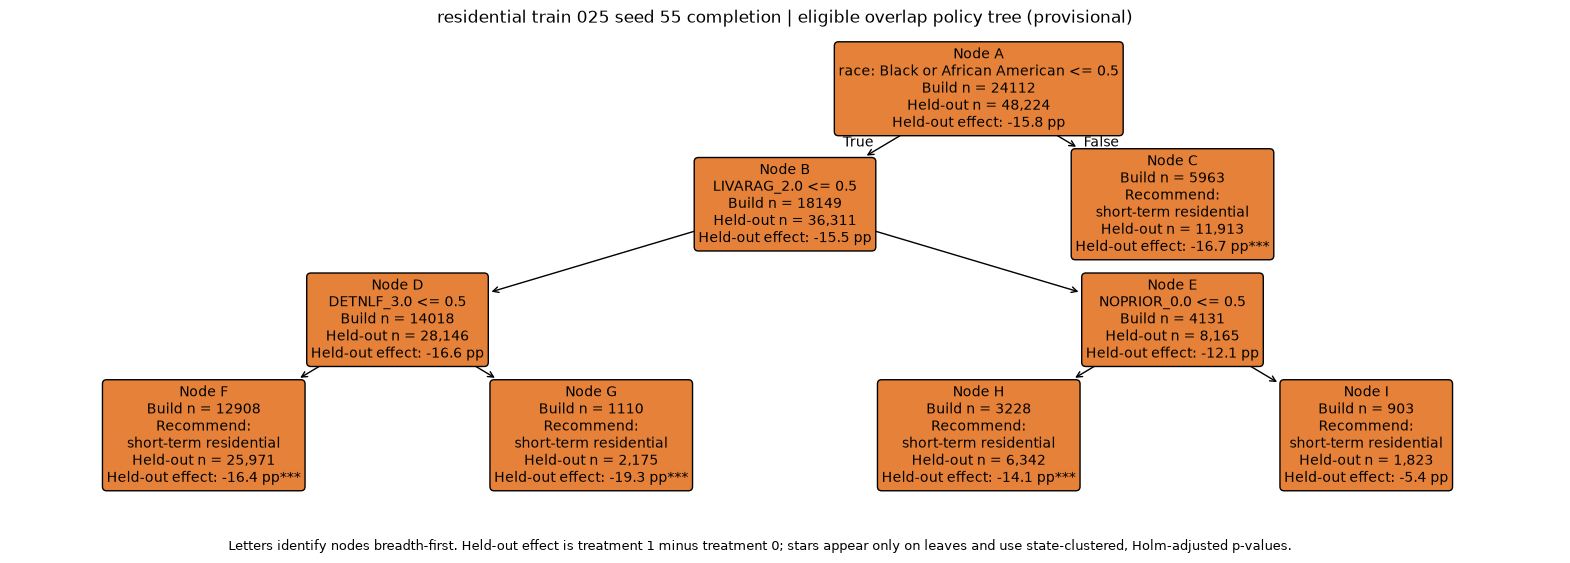

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,residential_train_025_seed_55,tree,48224,0.622078,0.0,39821.074219
1,residential_train_025_seed_55,always_0,48224,0.622078,0.0,39821.074219
2,residential_train_025_seed_55,always_1,48224,0.464354,1.0,39821.074219


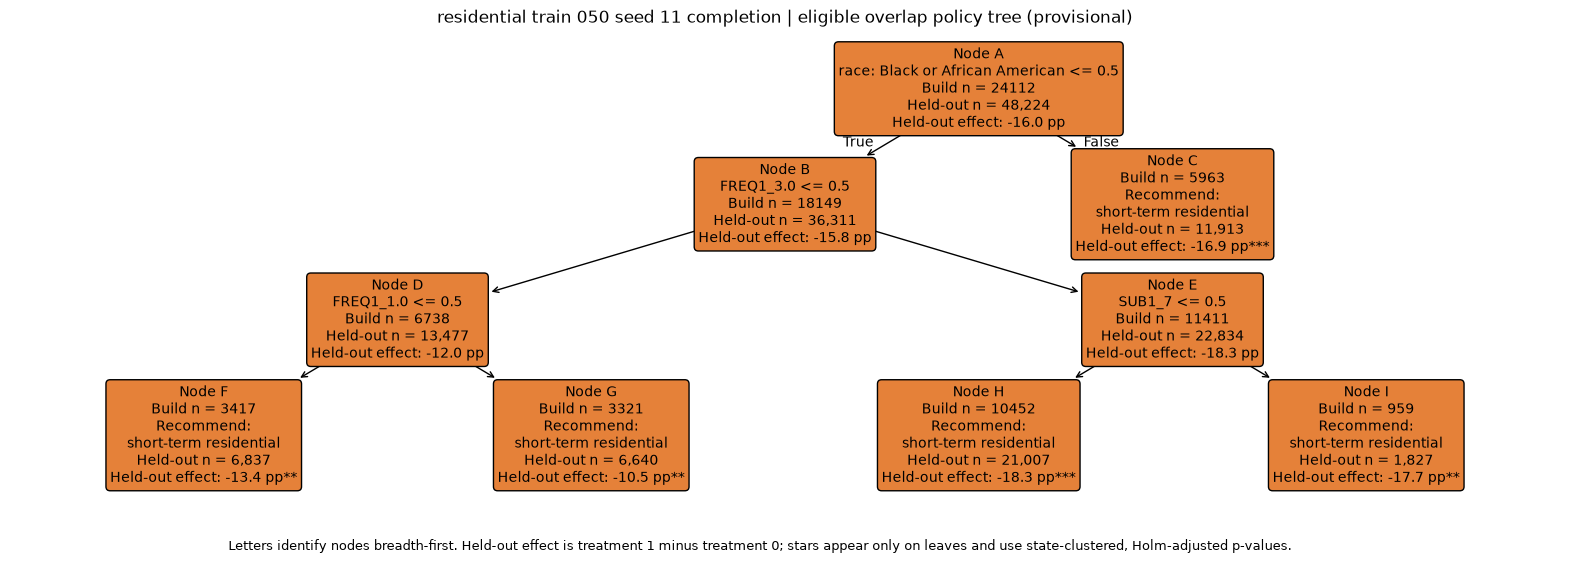

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,residential_train_050_seed_11,tree,48224,0.623415,0.0,39583.527344
1,residential_train_050_seed_11,always_0,48224,0.623415,0.0,39583.527344
2,residential_train_050_seed_11,always_1,48224,0.462976,1.0,39583.527344


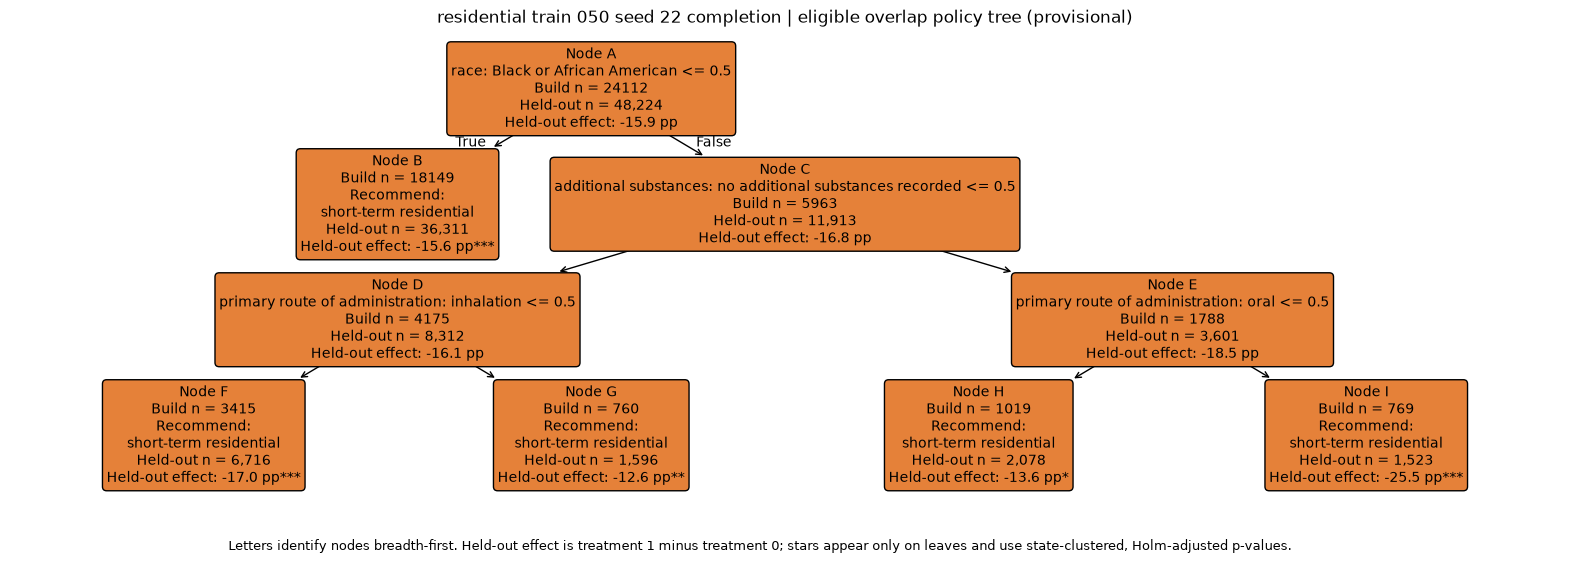

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,residential_train_050_seed_22,tree,48224,0.622866,0.0,39586.714844
1,residential_train_050_seed_22,always_0,48224,0.622866,0.0,39586.714844
2,residential_train_050_seed_22,always_1,48224,0.463928,1.0,39586.714844


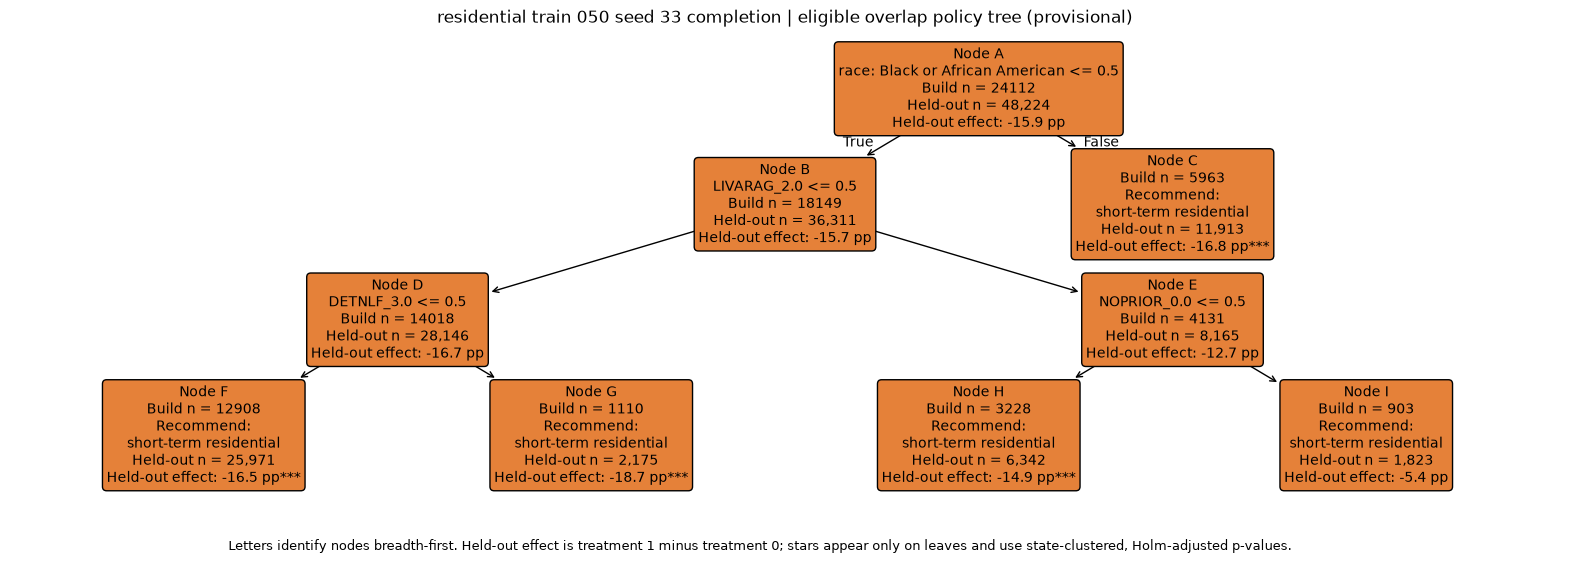

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,residential_train_050_seed_33,tree,48224,0.622943,0.0,39831.222656
1,residential_train_050_seed_33,always_0,48224,0.622943,0.0,39831.222656
2,residential_train_050_seed_33,always_1,48224,0.463461,1.0,39831.222656


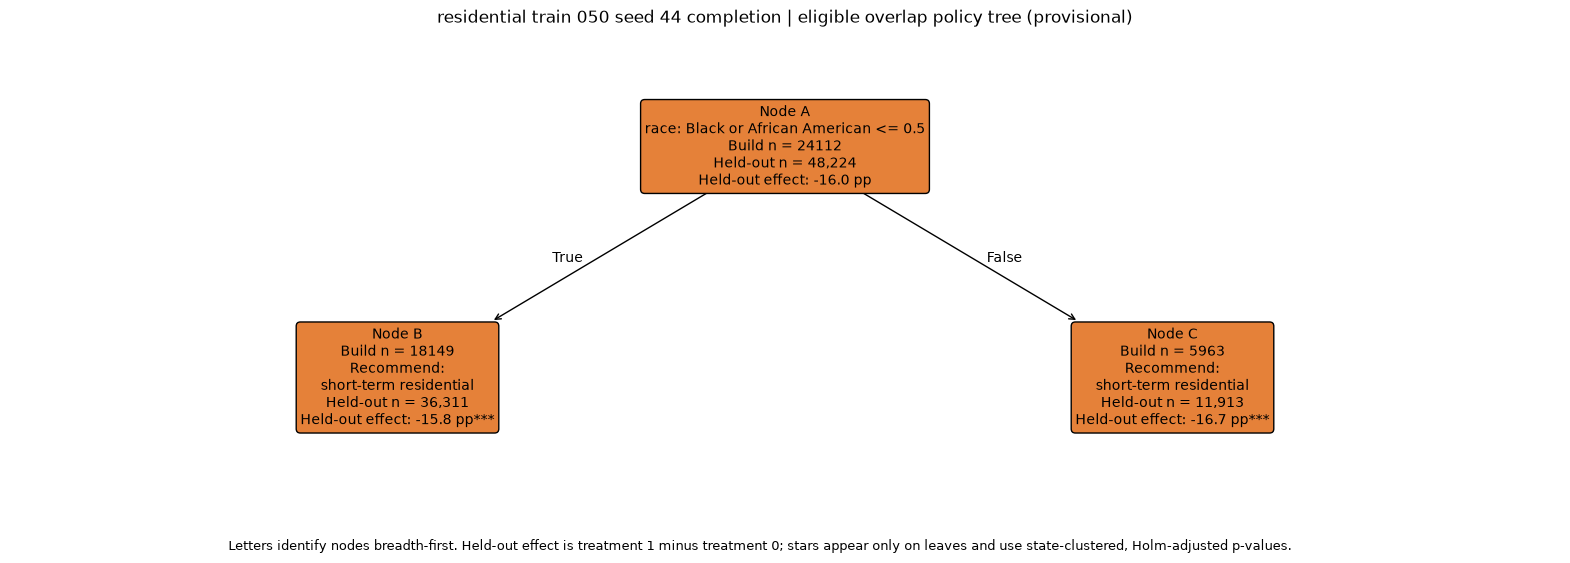

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,residential_train_050_seed_44,tree,48224,0.623125,0.0,39895.148438
1,residential_train_050_seed_44,always_0,48224,0.623125,0.0,39895.148438
2,residential_train_050_seed_44,always_1,48224,0.462769,1.0,39895.148438


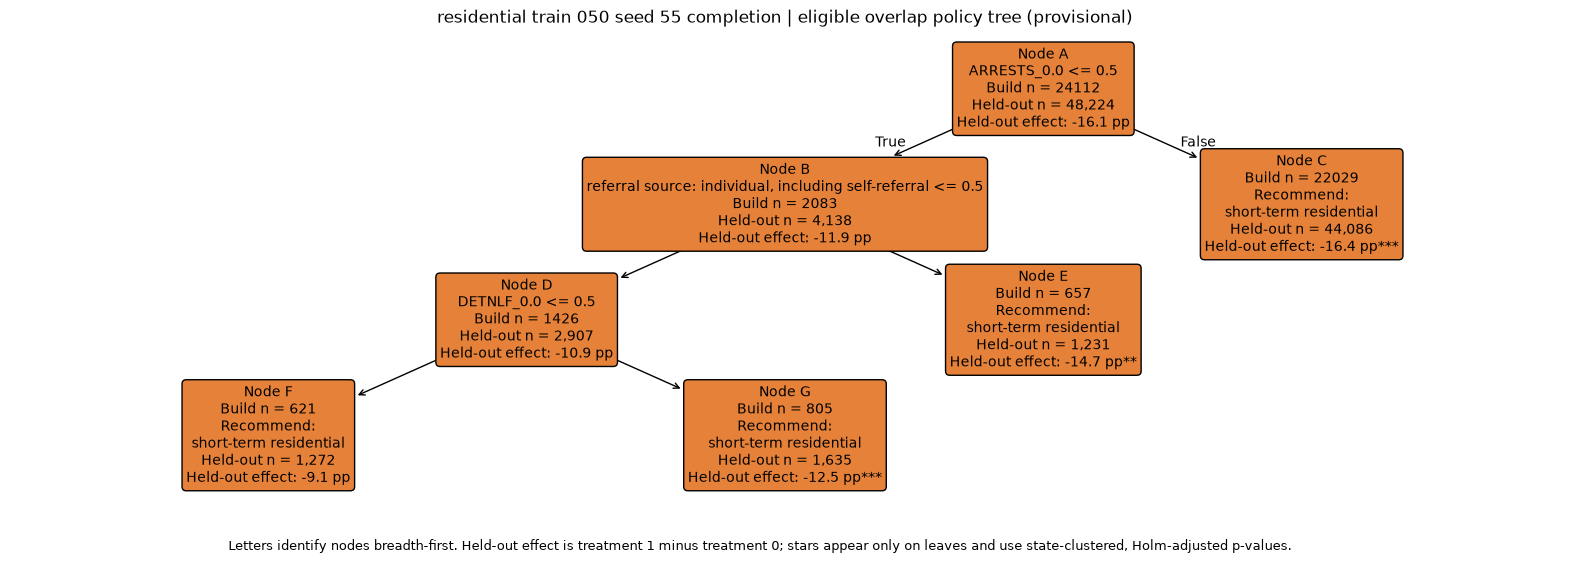

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,residential_train_050_seed_55,tree,48224,0.622531,0.0,39857.554688
1,residential_train_050_seed_55,always_0,48224,0.622531,0.0,39857.554688
2,residential_train_050_seed_55,always_1,48224,0.461970,1.0,39857.554688


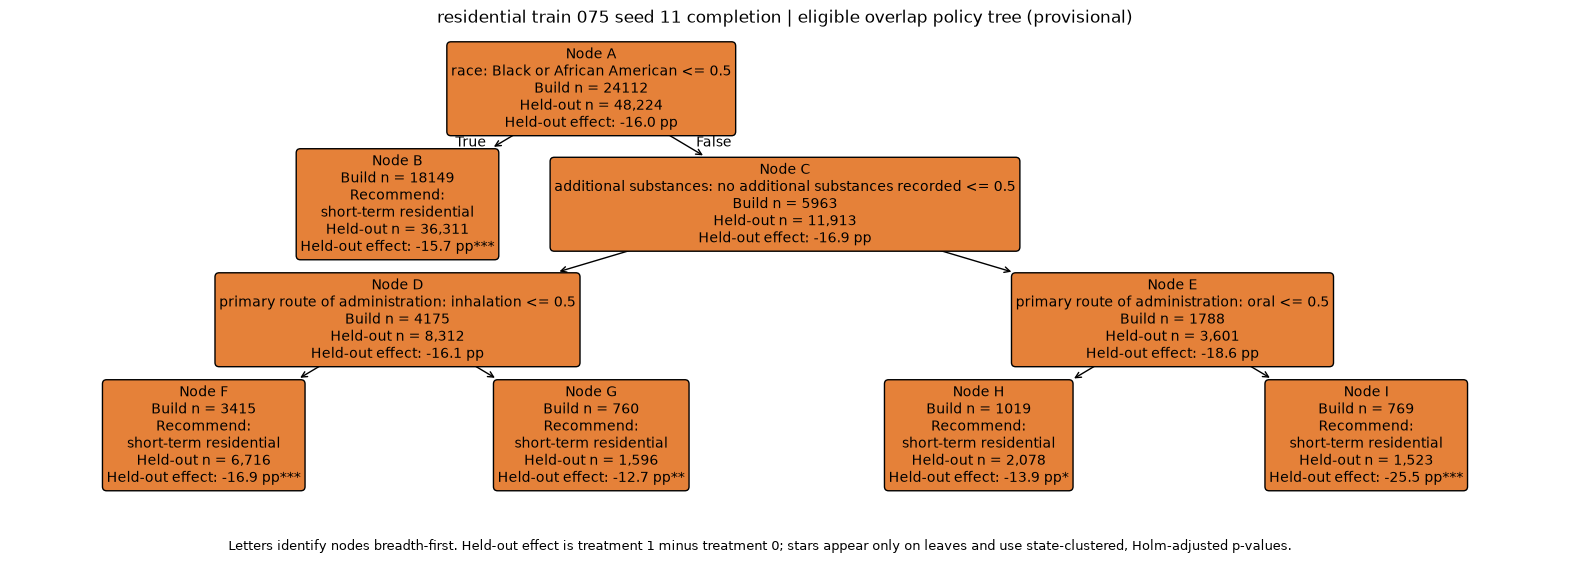

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,residential_train_075_seed_11,tree,48224,0.622664,0.0,39744.855469
1,residential_train_075_seed_11,always_0,48224,0.622664,0.0,39744.855469
2,residential_train_075_seed_11,always_1,48224,0.462822,1.0,39744.855469


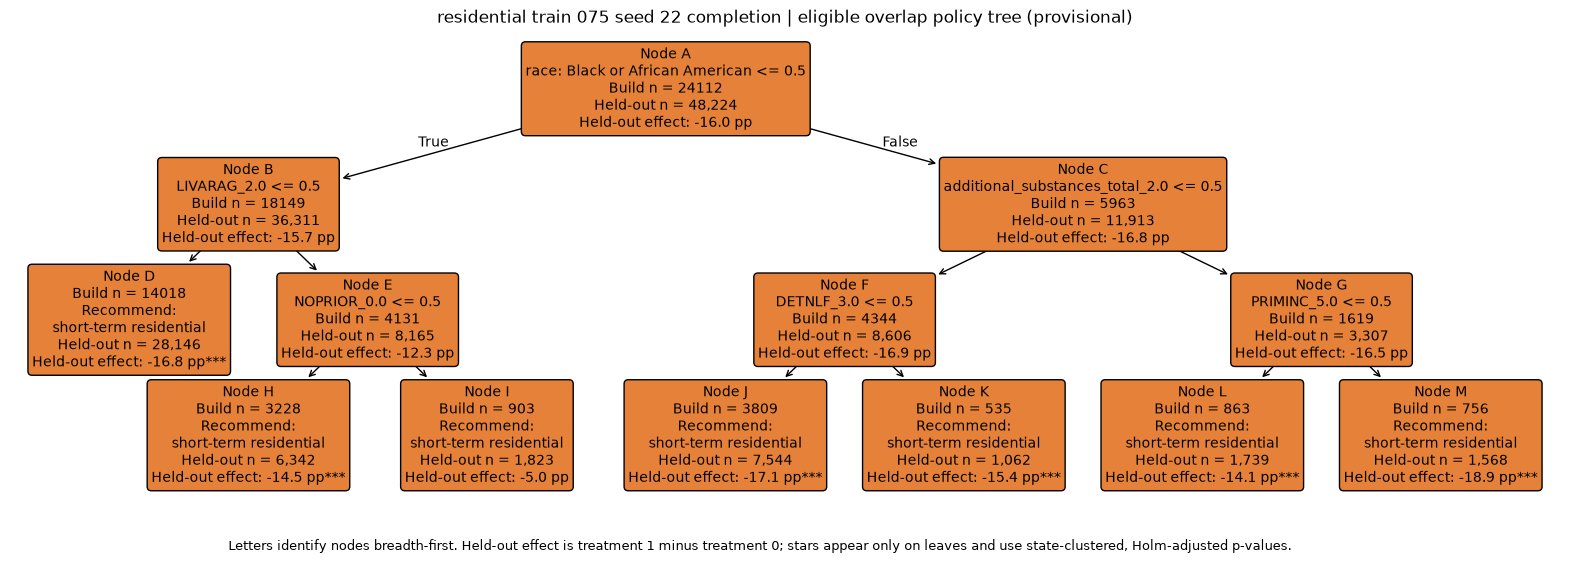

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,residential_train_075_seed_22,tree,48224,0.622239,0.0,39739.296875
1,residential_train_075_seed_22,always_0,48224,0.622239,0.0,39739.296875
2,residential_train_075_seed_22,always_1,48224,0.462713,1.0,39739.296875


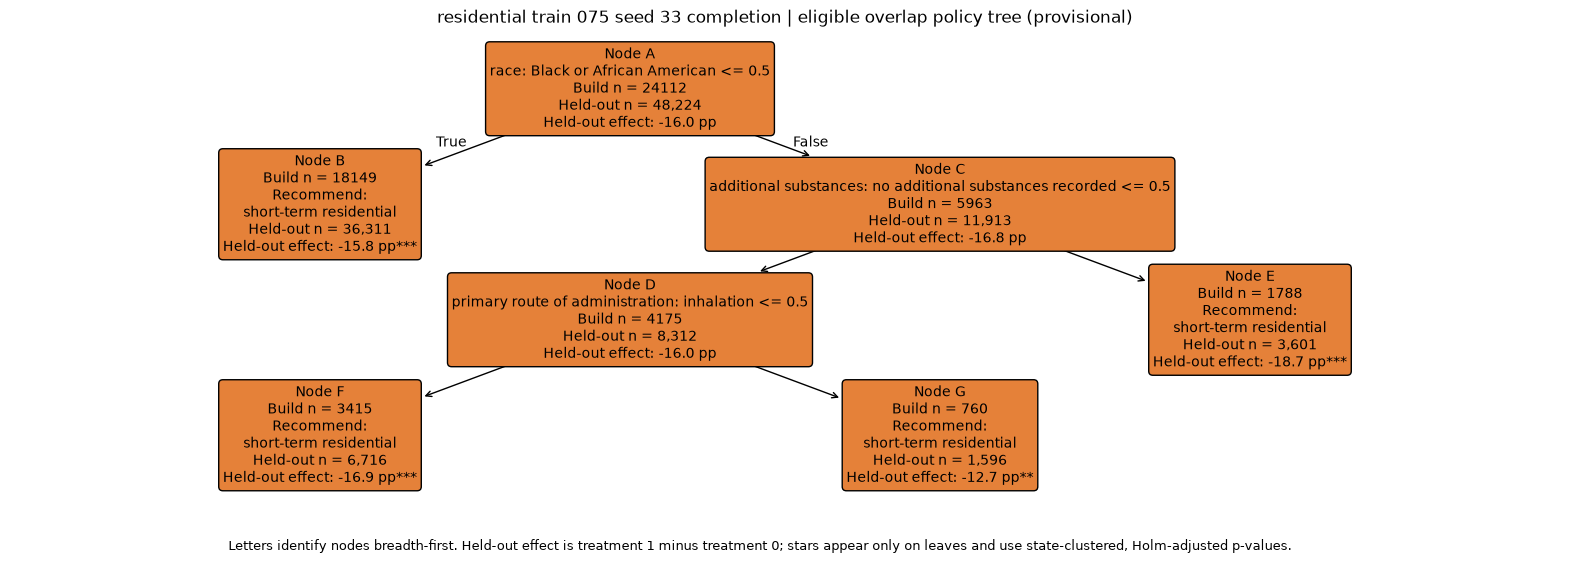

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,residential_train_075_seed_33,tree,48224,0.623238,0.0,39817.648438
1,residential_train_075_seed_33,always_0,48224,0.623238,0.0,39817.648438
2,residential_train_075_seed_33,always_1,48224,0.462747,1.0,39817.648438


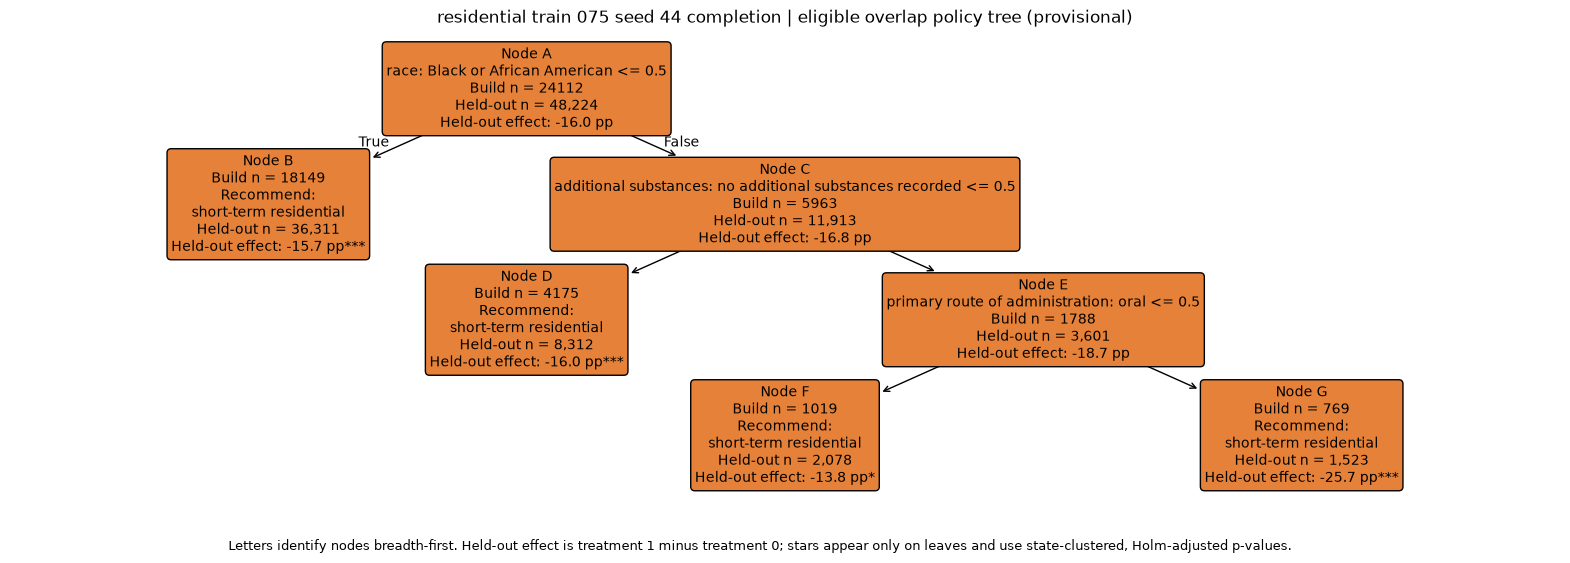

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,residential_train_075_seed_44,tree,48224,0.623292,0.0,39776.097656
1,residential_train_075_seed_44,always_0,48224,0.623292,0.0,39776.097656
2,residential_train_075_seed_44,always_1,48224,0.463297,1.0,39776.097656


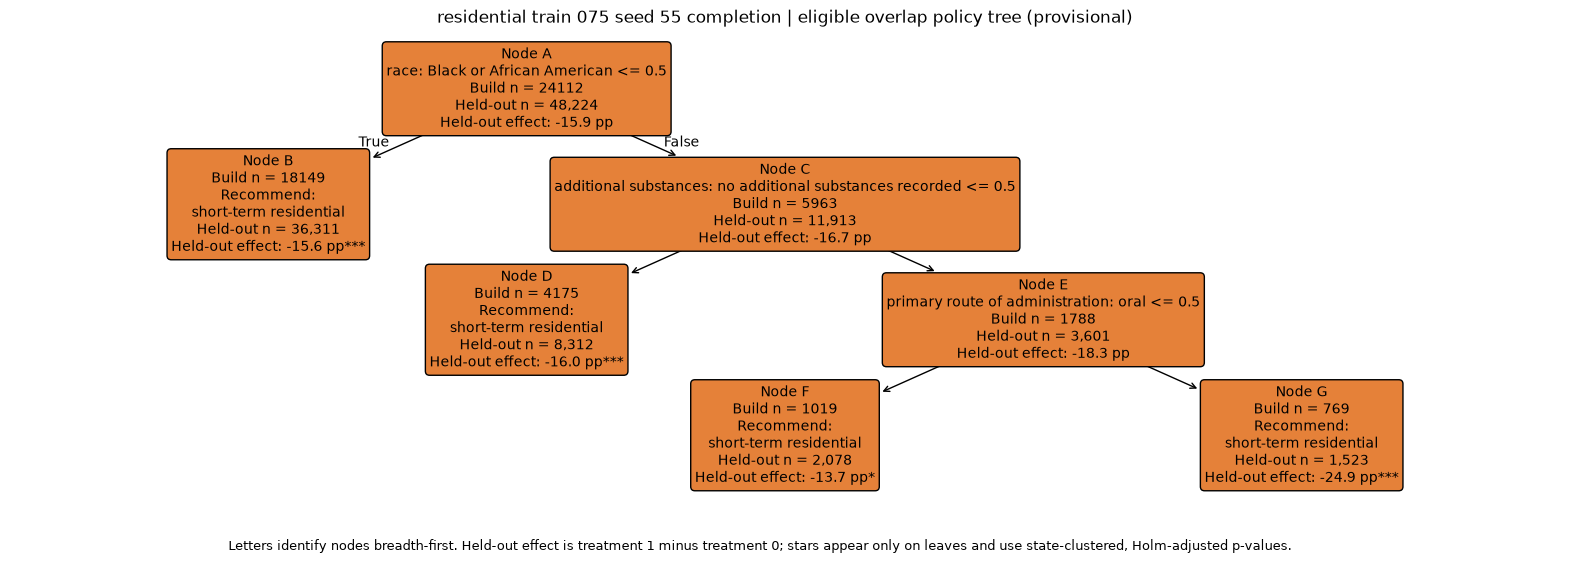

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,residential_train_075_seed_55,tree,48224,0.622354,0.0,39754.835938
1,residential_train_075_seed_55,always_0,48224,0.622354,0.0,39754.835938
2,residential_train_075_seed_55,always_1,48224,0.463312,1.0,39754.835938


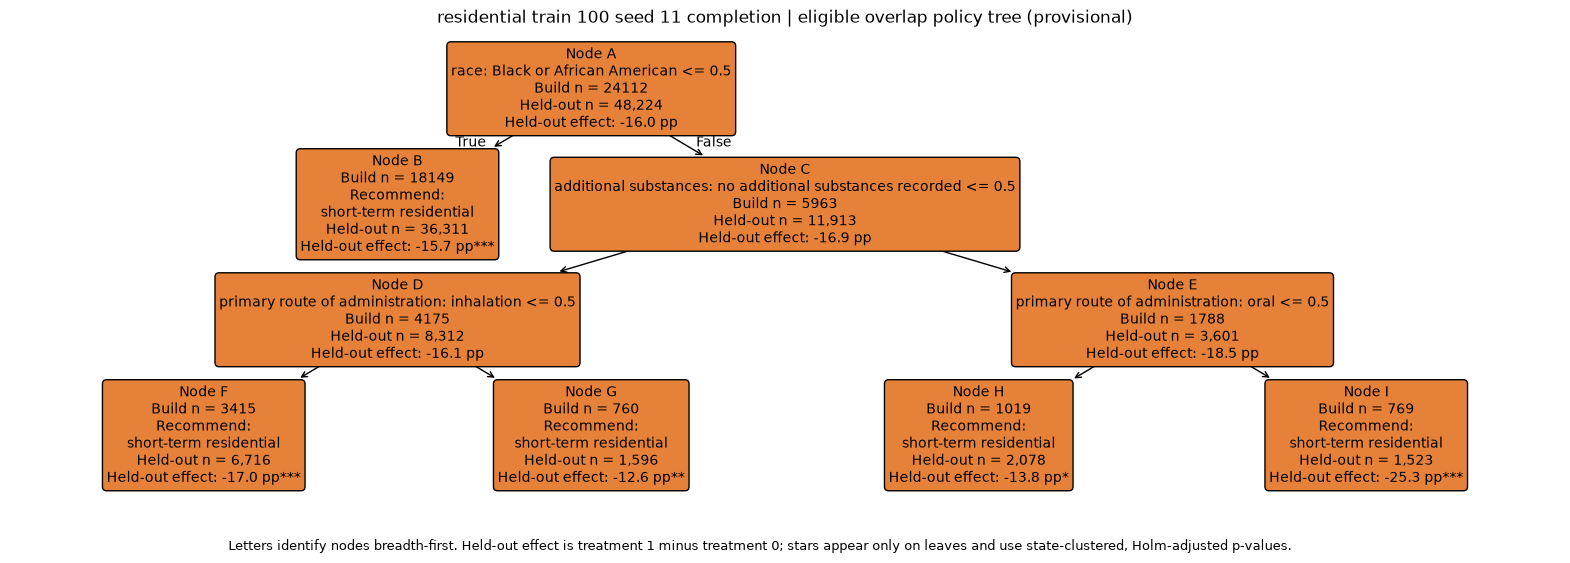

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,residential_train_100_seed_11,tree,48224,0.622752,0.0,39808.0625
1,residential_train_100_seed_11,always_0,48224,0.622752,0.0,39808.0625
2,residential_train_100_seed_11,always_1,48224,0.462634,1.0,39808.0625


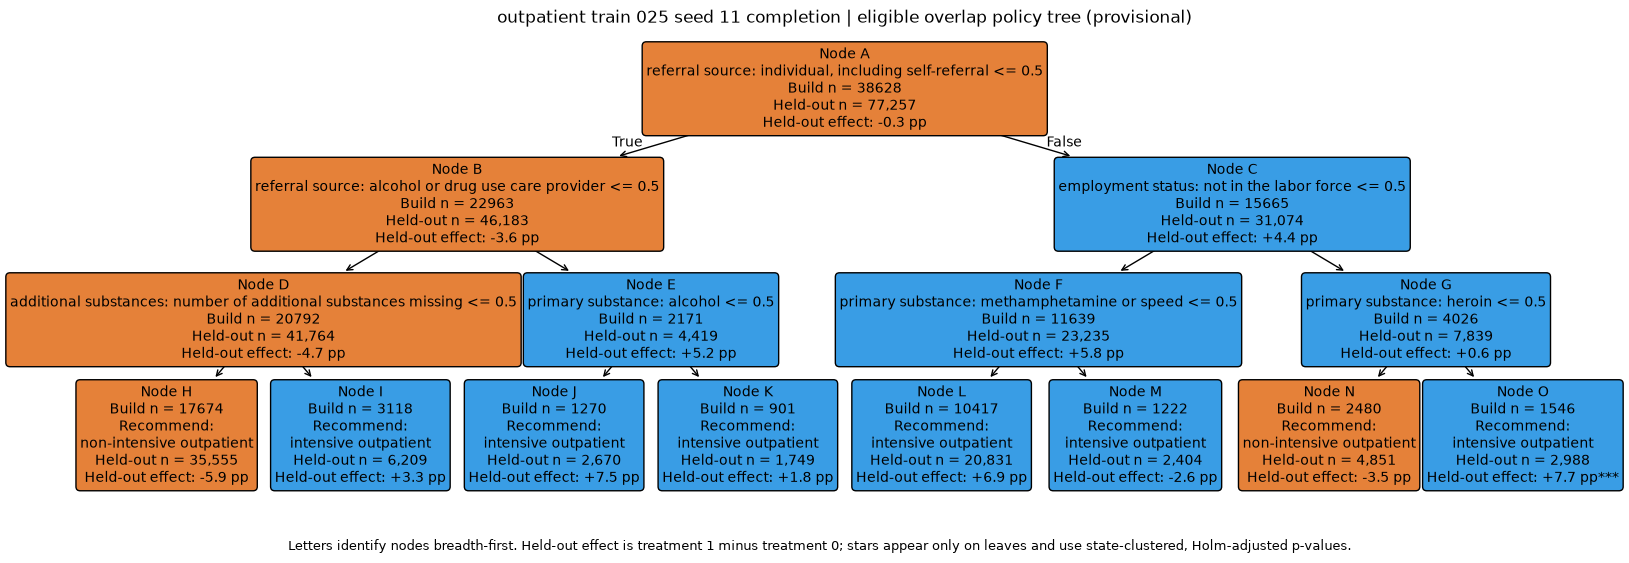

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_train_025_seed_11,tree,77257,0.333720,0.476992,72072.820312
1,outpatient_train_025_seed_11,always_0,77257,0.307673,0.000000,72072.820312
2,outpatient_train_025_seed_11,always_1,77257,0.304196,1.000000,72072.820312


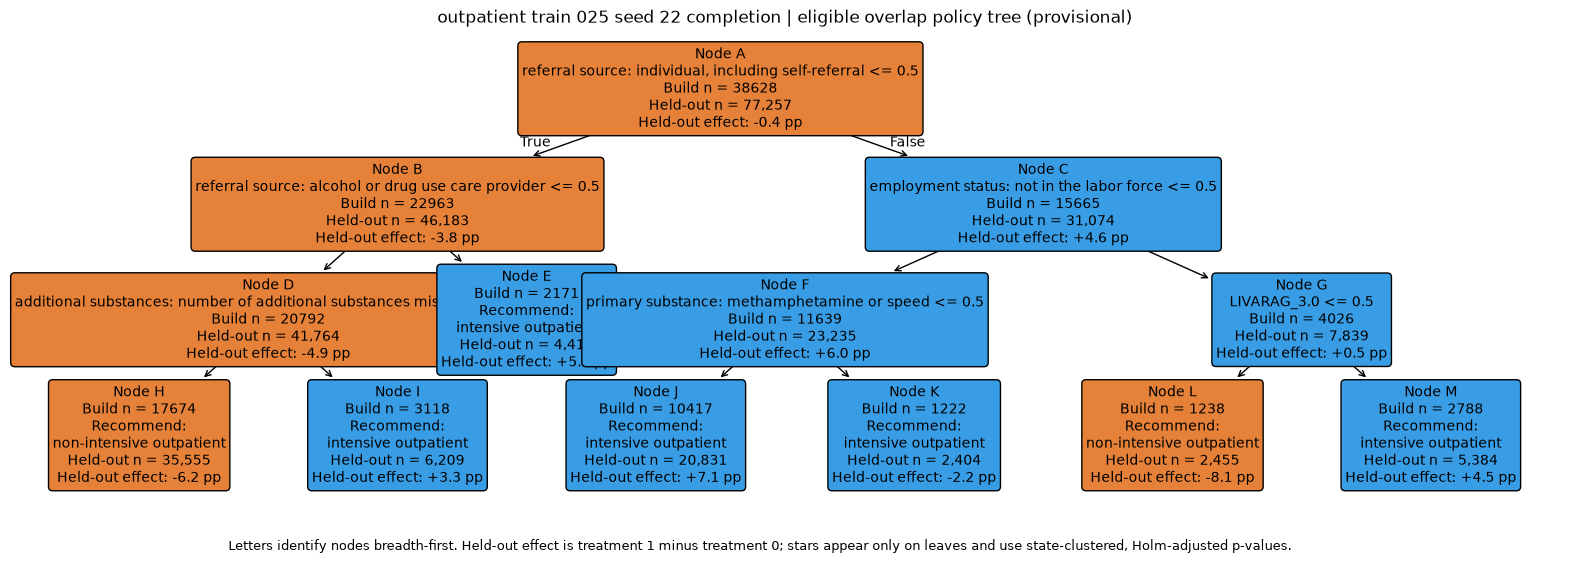

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_train_025_seed_22,tree,77257,0.335587,0.508006,72036.921875
1,outpatient_train_025_seed_22,always_0,77257,0.308243,0.000000,72036.921875
2,outpatient_train_025_seed_22,always_1,77257,0.304444,1.000000,72036.921875


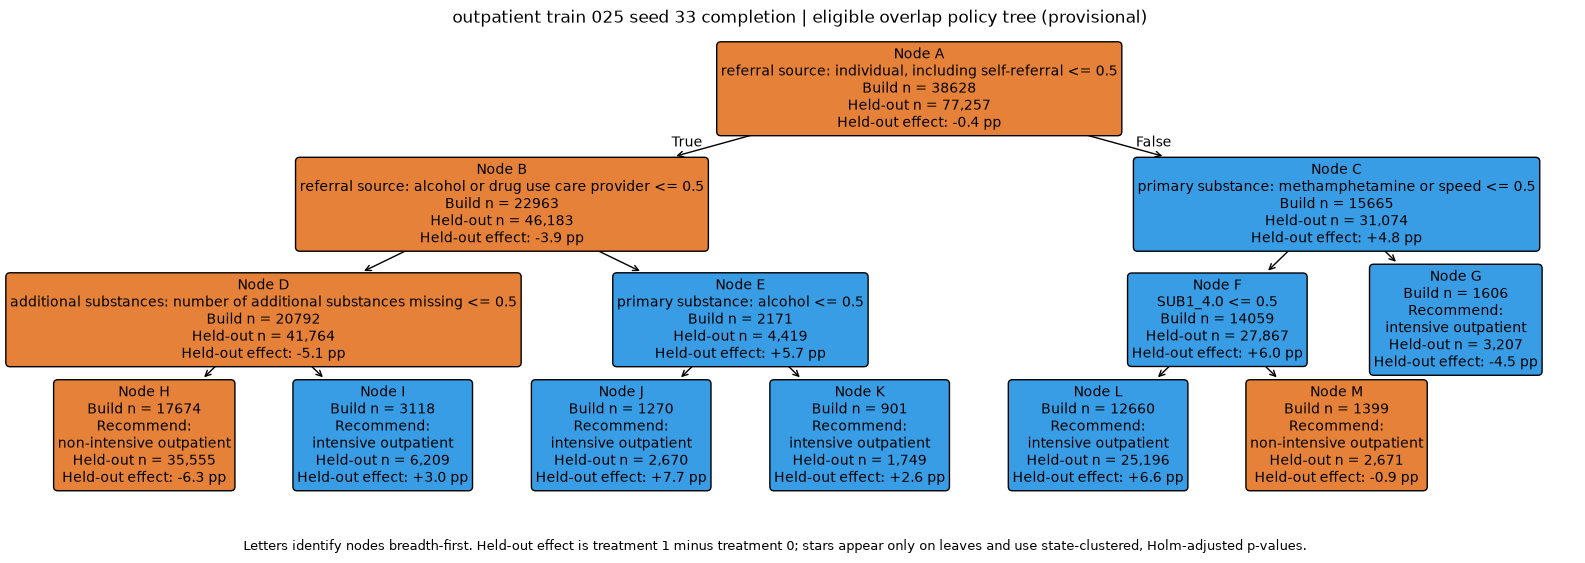

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_train_025_seed_33,tree,77257,0.332715,0.50521,72091.039062
1,outpatient_train_025_seed_33,always_0,77257,0.307242,0.00000,72091.039062
2,outpatient_train_025_seed_33,always_1,77257,0.303313,1.00000,72091.039062


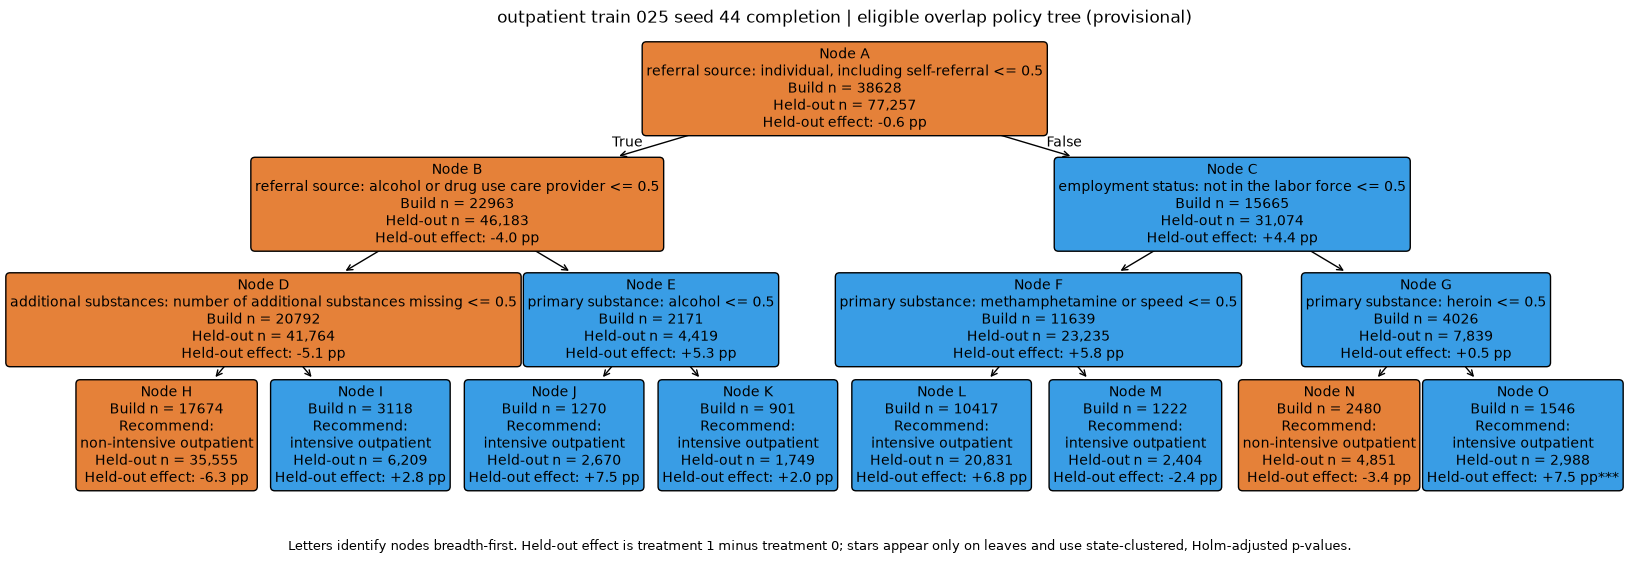

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_train_025_seed_44,tree,77257,0.333612,0.476992,72060.335938
1,outpatient_train_025_seed_44,always_0,77257,0.308214,0.000000,72060.335938
2,outpatient_train_025_seed_44,always_1,77257,0.301989,1.000000,72060.335938


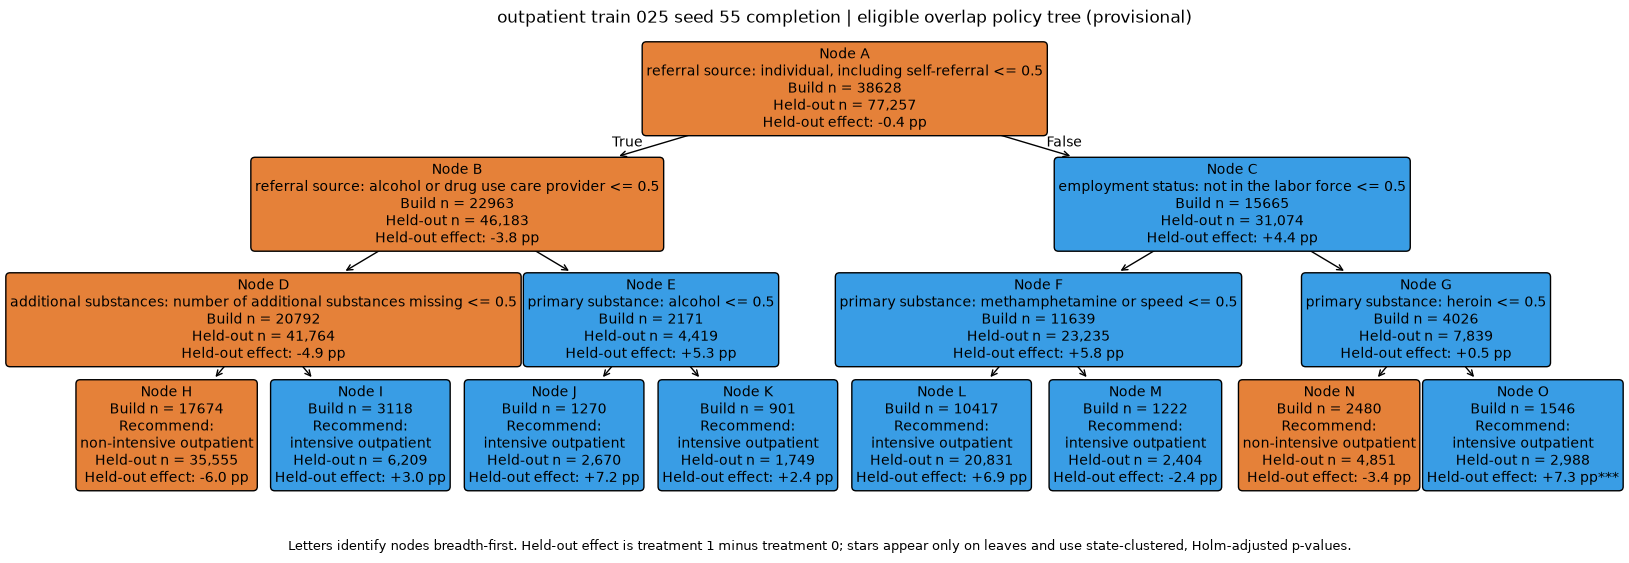

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_train_025_seed_55,tree,77257,0.333764,0.476992,71999.1875
1,outpatient_train_025_seed_55,always_0,77257,0.307996,0.000000,71999.1875
2,outpatient_train_025_seed_55,always_1,77257,0.303625,1.000000,71999.1875


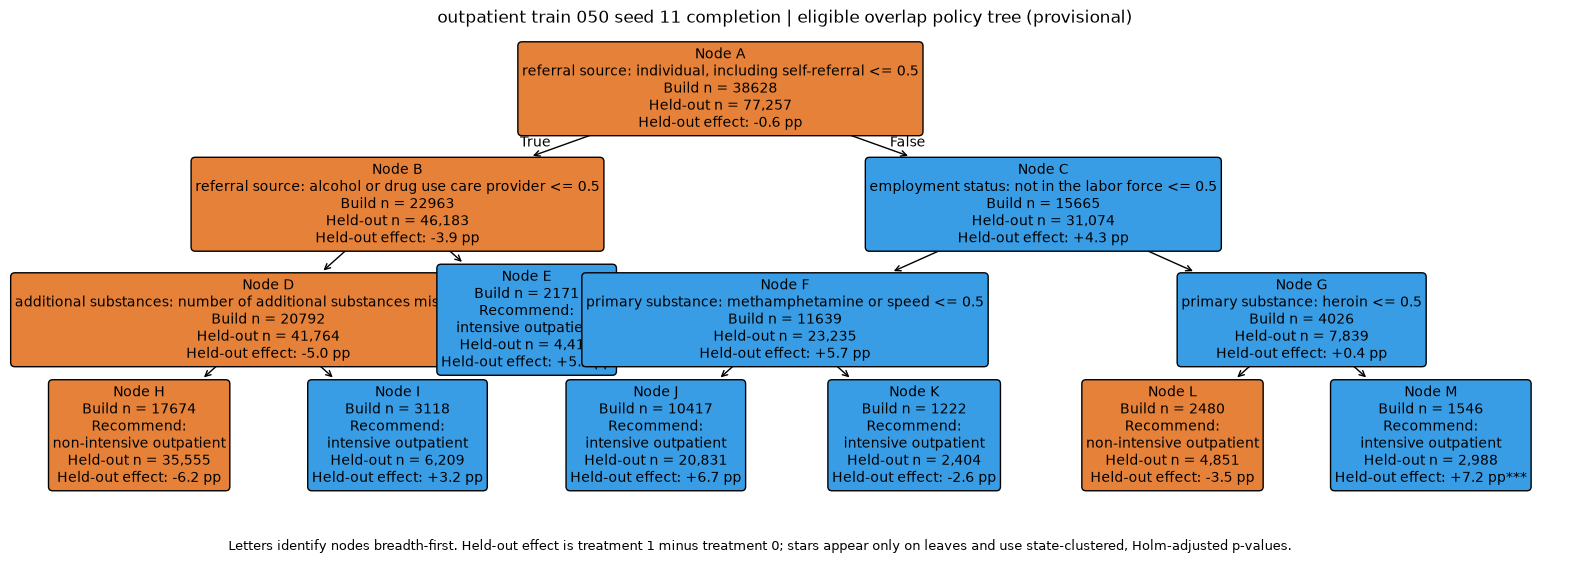

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_train_050_seed_11,tree,77257,0.332760,0.476992,72082.960938
1,outpatient_train_050_seed_11,always_0,77257,0.307499,0.000000,72082.960938
2,outpatient_train_050_seed_11,always_1,77257,0.301864,1.000000,72082.960938


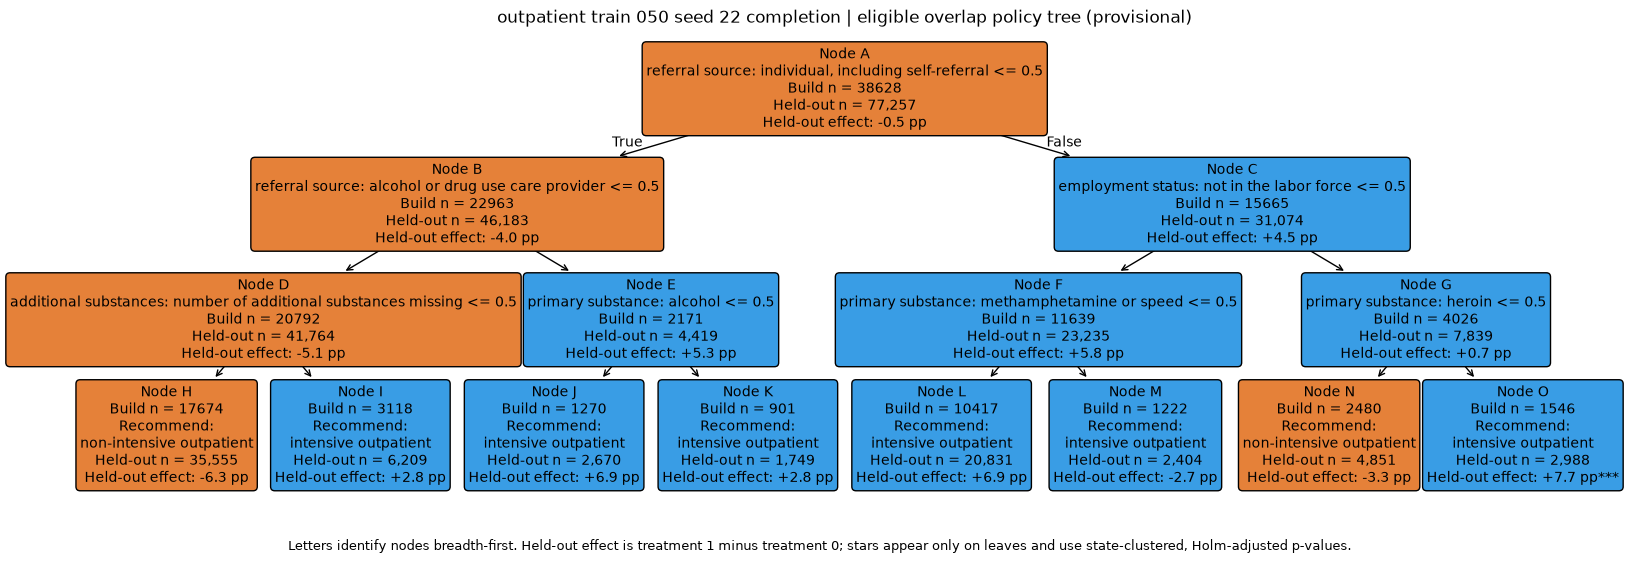

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_train_050_seed_22,tree,77257,0.333192,0.476992,72102.289062
1,outpatient_train_050_seed_22,always_0,77257,0.307500,0.000000,72102.289062
2,outpatient_train_050_seed_22,always_1,77257,0.302135,1.000000,72102.289062


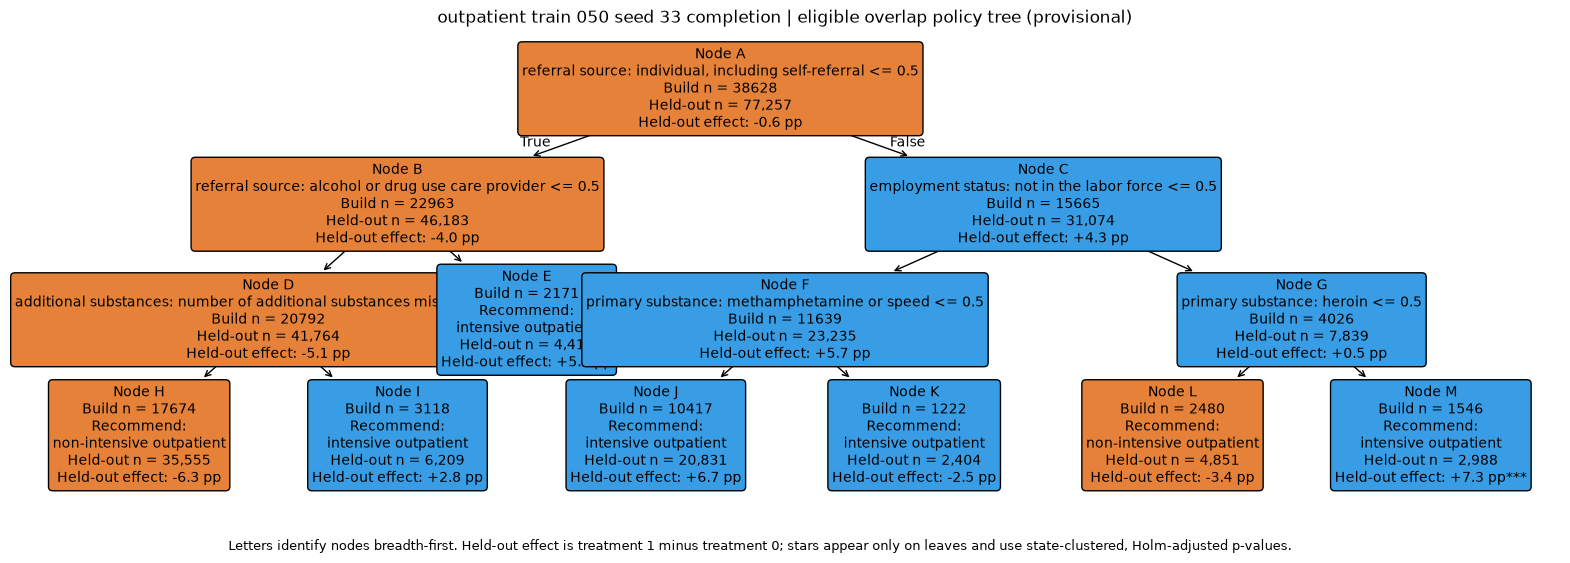

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_train_050_seed_33,tree,77257,0.332510,0.476992,72140.195312
1,outpatient_train_050_seed_33,always_0,77257,0.307258,0.000000,72140.195312
2,outpatient_train_050_seed_33,always_1,77257,0.301302,1.000000,72140.195312


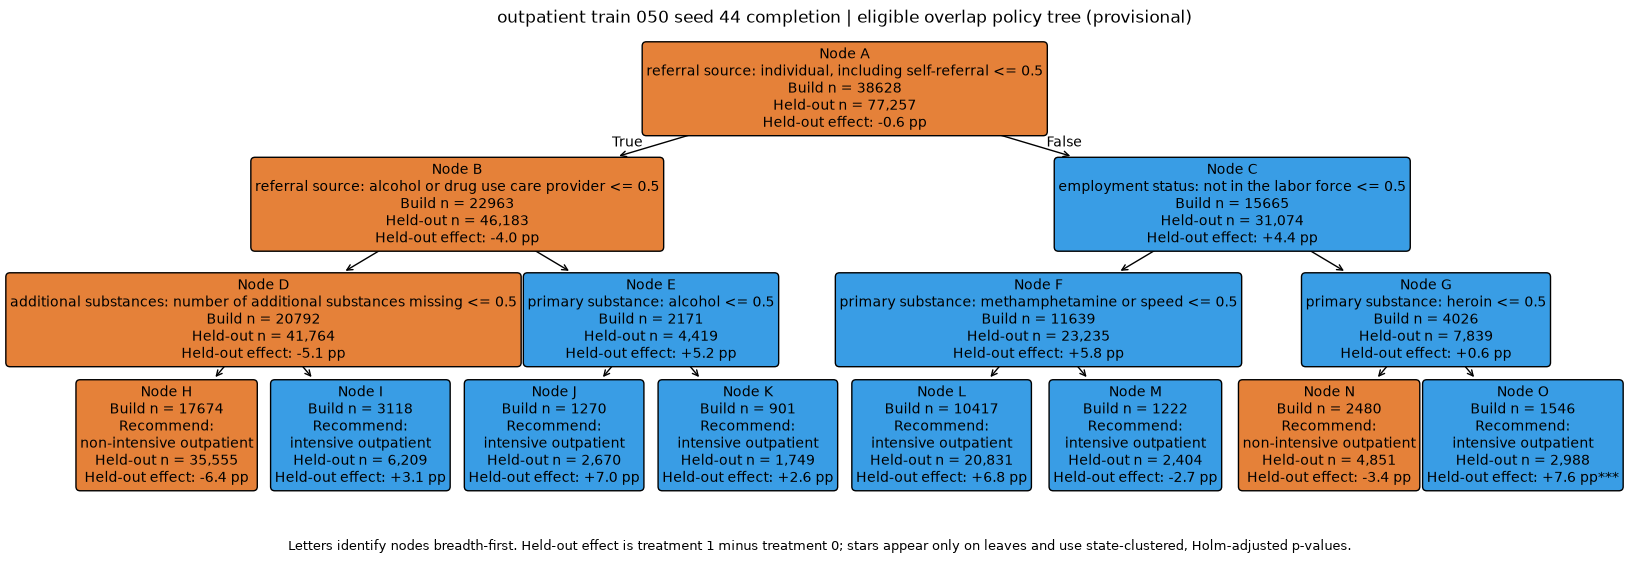

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_train_050_seed_44,tree,77257,0.333411,0.476992,72096.304688
1,outpatient_train_050_seed_44,always_0,77257,0.307742,0.000000,72096.304688
2,outpatient_train_050_seed_44,always_1,77257,0.301714,1.000000,72096.304688


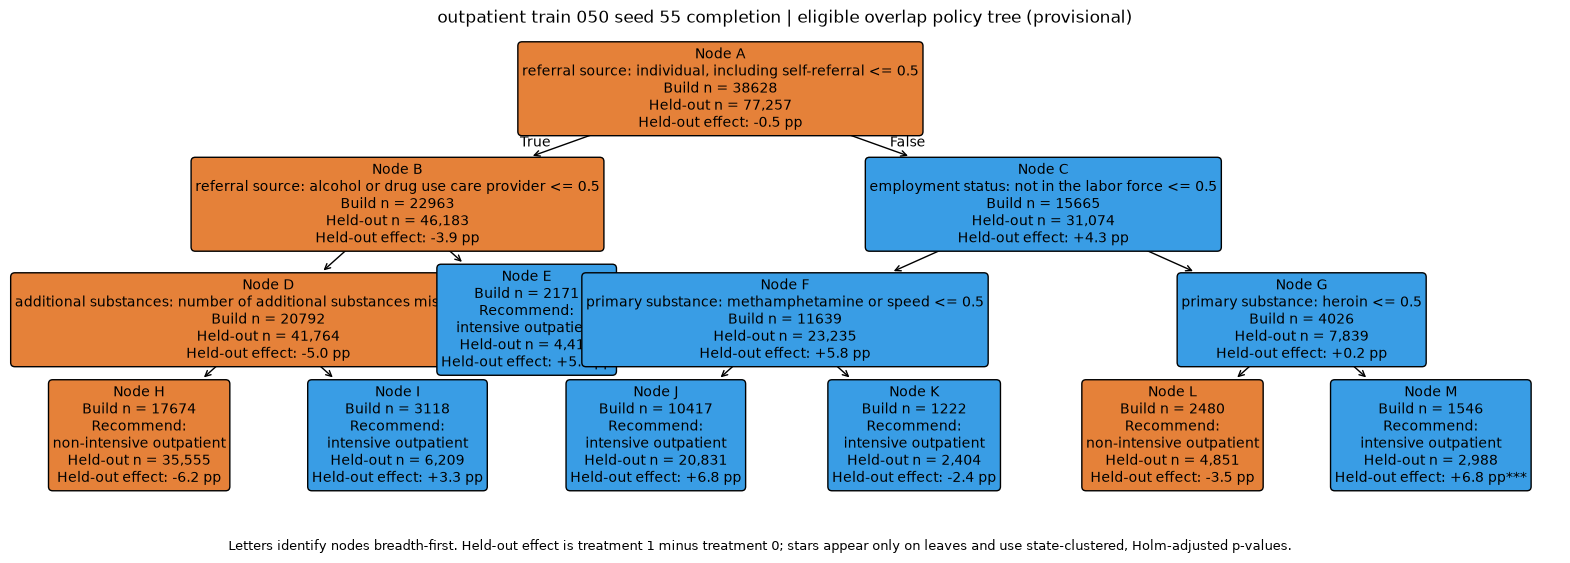

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_train_050_seed_55,tree,77257,0.333096,0.476992,71941.726562
1,outpatient_train_050_seed_55,always_0,77257,0.307584,0.000000,71941.726562
2,outpatient_train_050_seed_55,always_1,77257,0.302091,1.000000,71941.726562


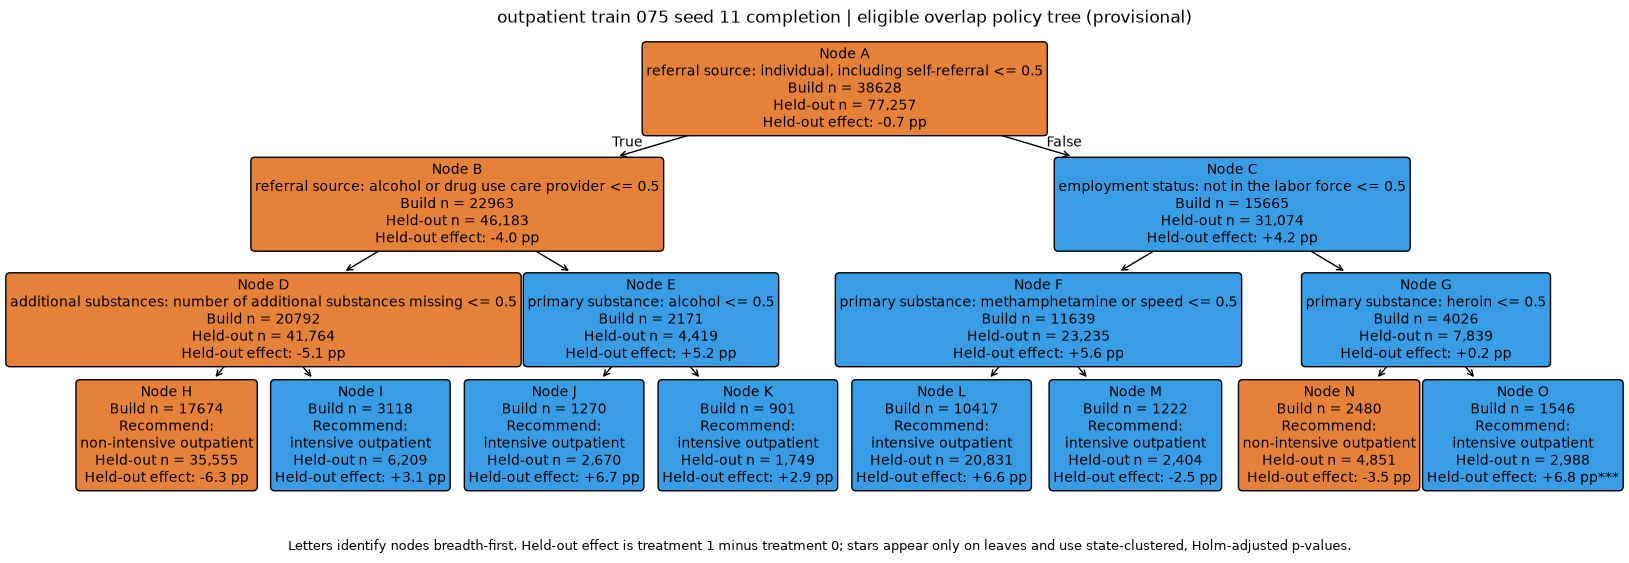

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_train_075_seed_11,tree,77257,0.332226,0.476992,72025.929688
1,outpatient_train_075_seed_11,always_0,77257,0.307353,0.000000,72025.929688
2,outpatient_train_075_seed_11,always_1,77257,0.300790,1.000000,72025.929688


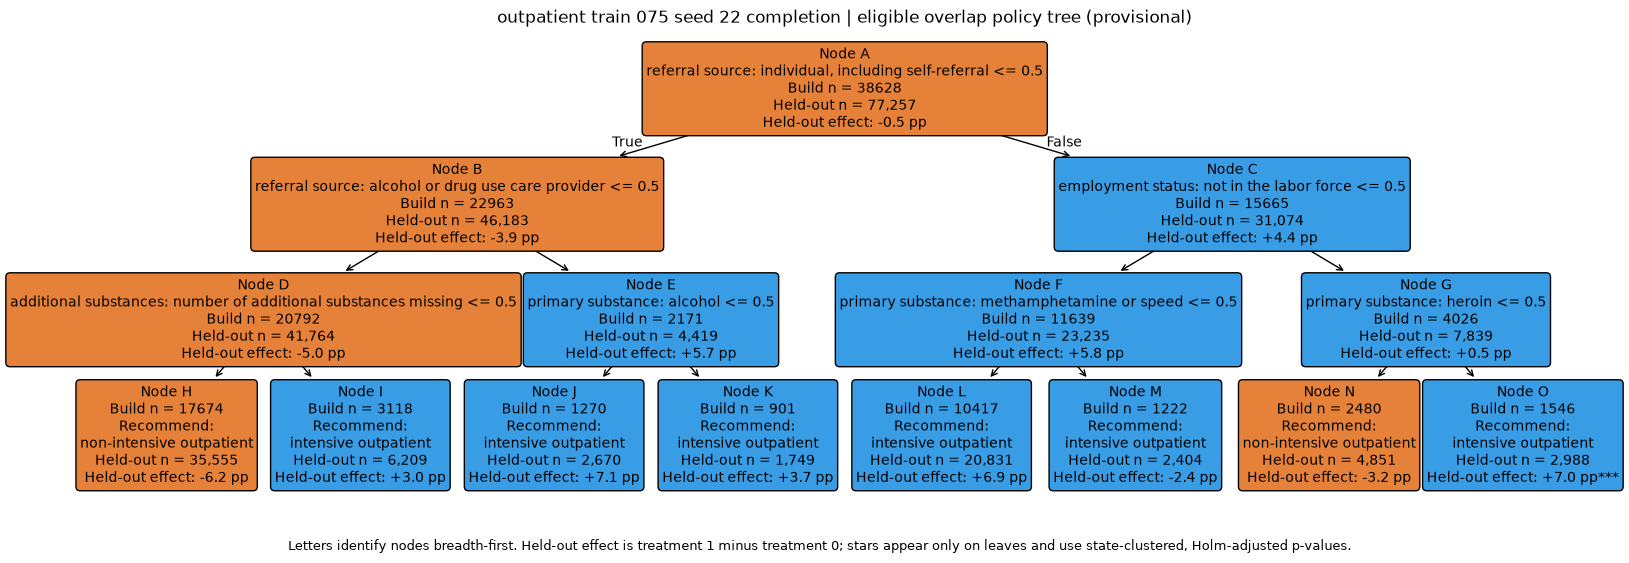

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_train_075_seed_22,tree,77257,0.332413,0.476992,72056.742188
1,outpatient_train_075_seed_22,always_0,77257,0.306548,0.000000,72056.742188
2,outpatient_train_075_seed_22,always_1,77257,0.301498,1.000000,72056.742188


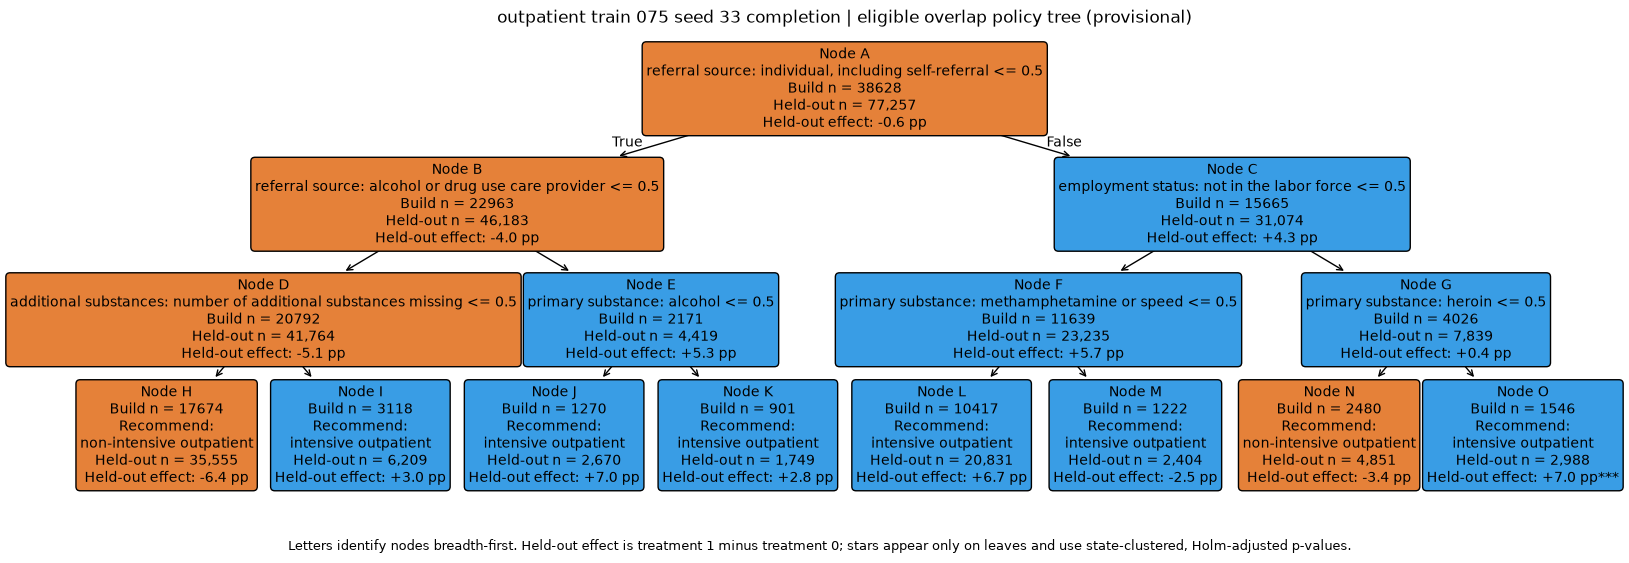

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_train_075_seed_33,tree,77257,0.332792,0.476992,72069.101562
1,outpatient_train_075_seed_33,always_0,77257,0.307576,0.000000,72069.101562
2,outpatient_train_075_seed_33,always_1,77257,0.301091,1.000000,72069.101562


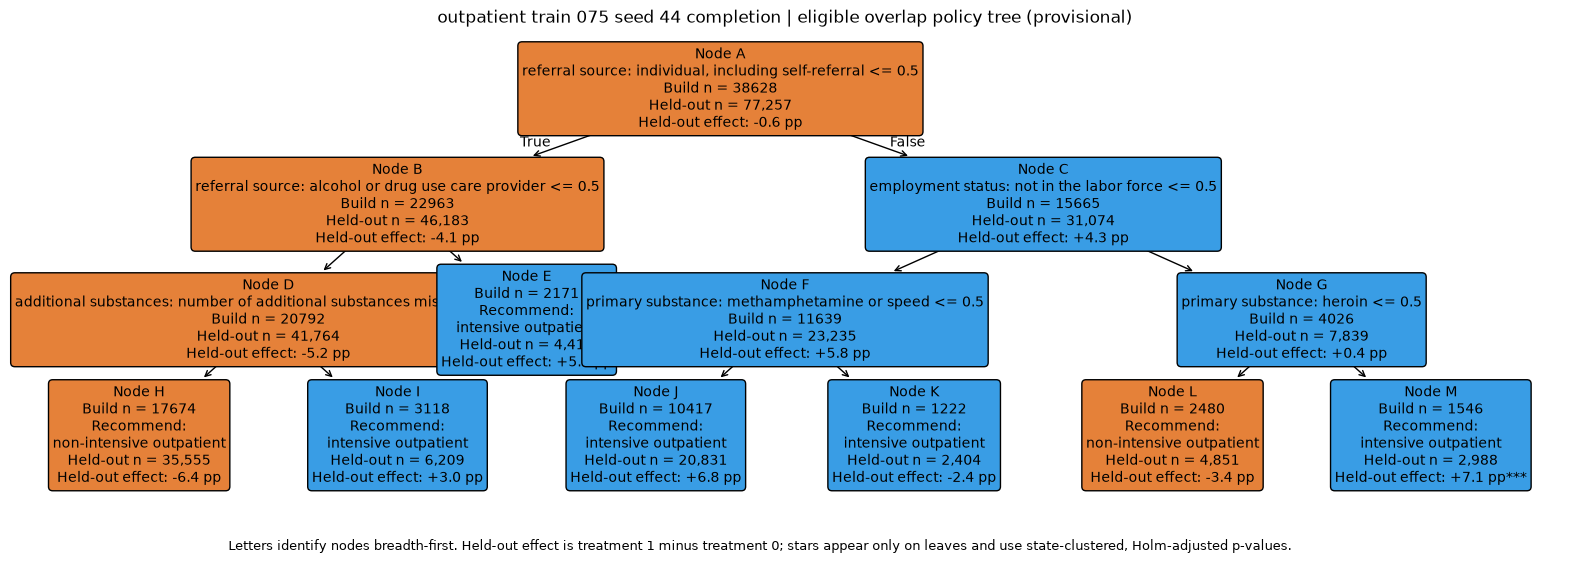

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_train_075_seed_44,tree,77257,0.333044,0.476992,72062.84375
1,outpatient_train_075_seed_44,always_0,77257,0.307652,0.000000,72062.84375
2,outpatient_train_075_seed_44,always_1,77257,0.301155,1.000000,72062.84375


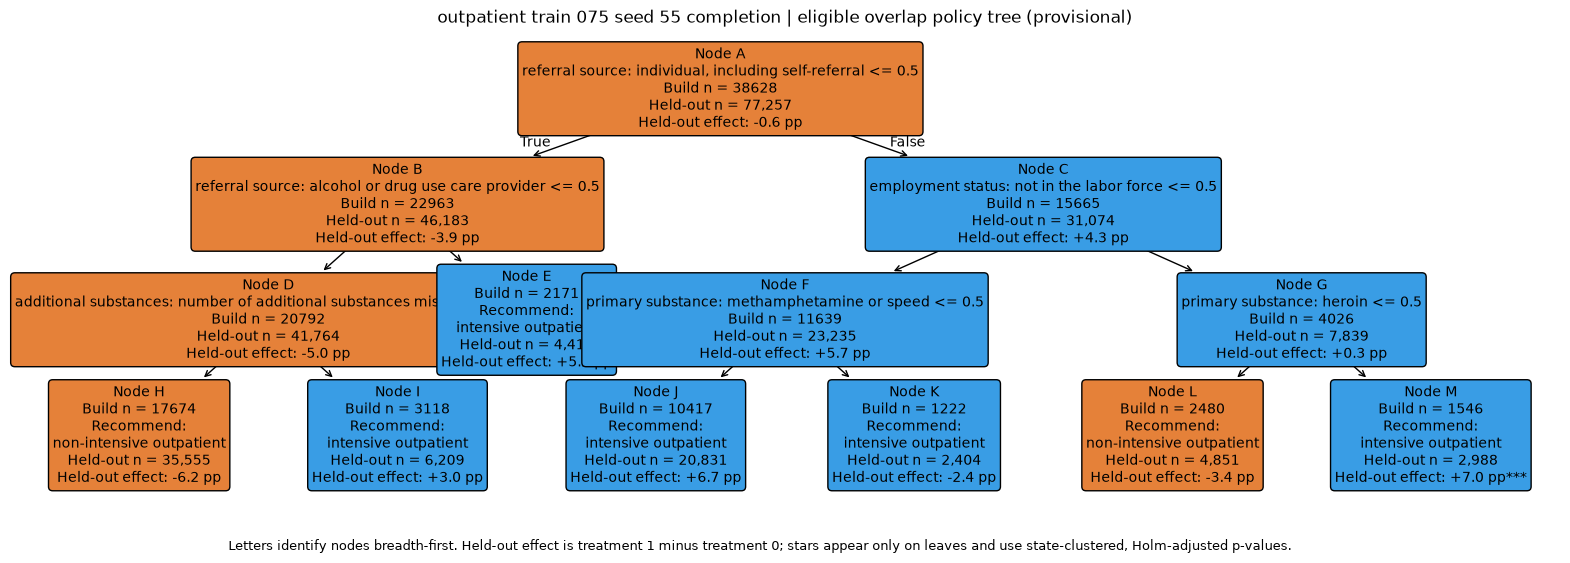

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_train_075_seed_55,tree,77257,0.332694,0.476992,72000.804688
1,outpatient_train_075_seed_55,always_0,77257,0.307557,0.000000,72000.804688
2,outpatient_train_075_seed_55,always_1,77257,0.301670,1.000000,72000.804688


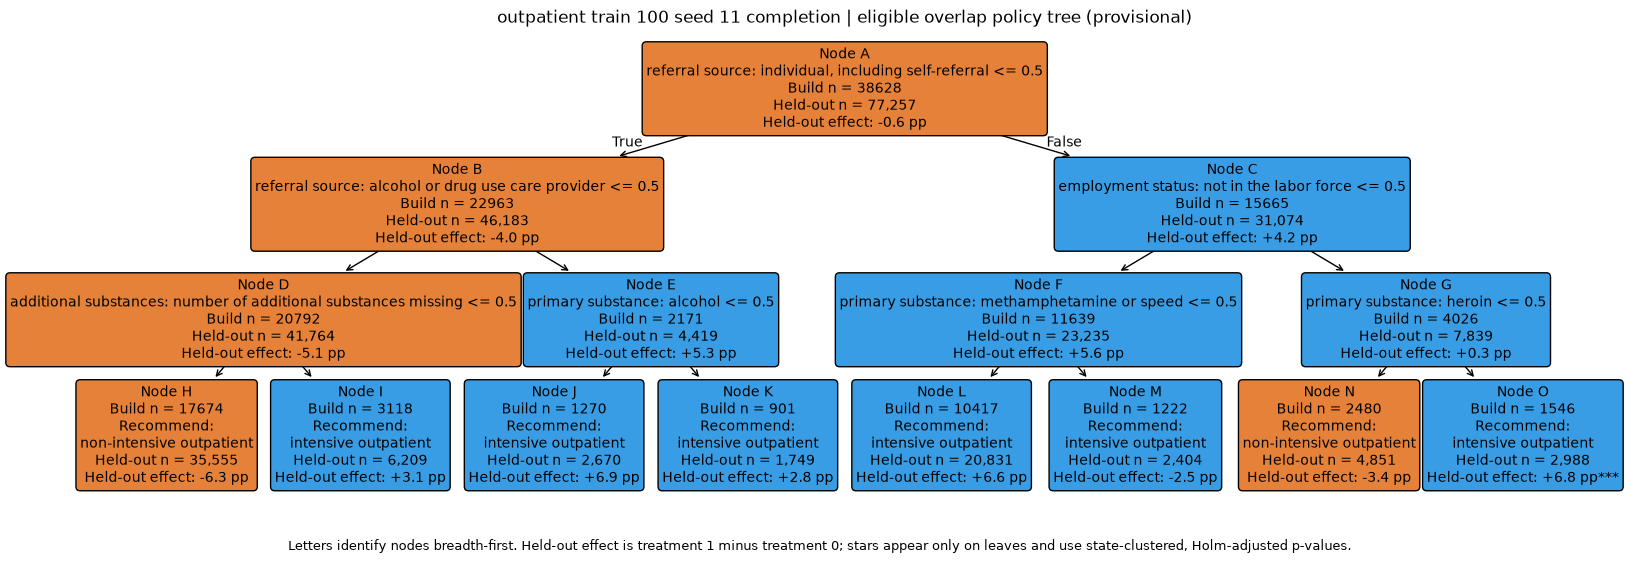

,branch,policy,n,overlap_value,intensive_or_long_share,overlap_ess
0,outpatient_train_100_seed_11,tree,77257,0.332439,0.476992,72082.007812
1,outpatient_train_100_seed_11,always_0,77257,0.307499,0.000000,72082.007812
2,outpatient_train_100_seed_11,always_1,77257,0.301067,1.000000,72082.007812


In [3]:
# Historical SA07 grid transferred to the current service-setting treatment contrasts.
BASELINE=HOME/'outputs/S1_02_policy_trees_20260926_195240_351369'
SEEDS=(11,22,33,44,55)
FRACTIONS=(.25,.50,.75,1.0)
rows=[]
for branch in ('residential','outpatient'):
    info=dict(BRANCHES[branch]);info['file']=info['eligible_file'];info['expected_n']=info['eligible_n']
    d=prepare_sample(branch,info,'eligible')
    prior_tag=f'{branch}_eligible'
    old=pd.read_csv(BASELINE/f'{prior_tag}_split.csv.gz')
    assert old.episode_source_id.astype(str).equals(d.episode_source_id.astype(str))
    full_roles={role:np.flatnonzero(old.role.eq(role).to_numpy()) for role in ('train','build','test')}
    assert all(len(v)>0 for v in full_roles.values())
    baseline=pd.read_csv(BASELINE/prior_tag/'holdout_assignments.csv.gz')
    baseline_values=pd.read_csv(BASELINE/prior_tag/'holdout_policy_value.csv').set_index('policy')
    grouping=d.STFIPS.astype(str)+'_'+d.DISYR.astype(str)+'_'+d.treatment.astype(int).astype(str)
    for fraction in FRACTIONS:
        for seed in (SEEDS[:1] if fraction==1.0 else SEEDS):
            tag=f'{branch}_train_{int(fraction*100):03d}_seed_{seed}'
            roles=dict(full_roles)
            if fraction<1:
                selected,_=train_test_split(full_roles['train'],train_size=fraction,random_state=seed,
                                             stratify=grouping.iloc[full_roles['train']])
                roles['train']=np.sort(selected)
            assert not set(roles['train']) & set(roles['test'])
            assert not set(roles['train']) & set(roles['build'])
            dest=RUN/tag
            if (dest/'manifest.json').is_file():
                existing=json.loads((dest/'manifest.json').read_text())
                assert existing['sample_membership_sha256']==json.loads((BASELINE/prior_tag/'manifest.json').read_text())['sample_membership_sha256']
                assert all(sha(dest/name)==expected for name,expected in existing['files'].items())
                value=pd.read_csv(dest/'holdout_policy_value.csv')
                print('Reused verified fit:',tag)
            else:
                result,value=fit_branch(tag,info,d,roles,'eligible')
            holdout=pd.read_csv(dest/'holdout_assignments.csv.gz')
            assert holdout.episode_source_id.equals(baseline.episode_source_id)
            assert len(holdout)==len(full_roles['test'])
            indexed=value.set_index('policy')
            gain=float(indexed.loc['tree','overlap_value']-max(indexed.loc['always_0','overlap_value'],indexed.loc['always_1','overlap_value']))
            rows.append({'branch':branch,'train_fraction':fraction,'sampling_seed':seed,'n_train':len(roles['train']),
                         'n_build':len(roles['build']),'n_test':len(roles['test']),
                         'policy_disagreement_vs_primary':float((holdout.policy!=baseline.policy).mean()),
                         'mean_abs_cate_change_vs_primary':float(np.abs(holdout.cate-baseline.cate).mean()),
                         'tree_treatment_1_share':float(indexed.loc['tree','intensive_or_long_share']),
                         'tree_minus_best_constant':gain,
                         'gain_difference_vs_primary':gain-float(baseline_values.loc['tree','overlap_value']-max(baseline_values.loc['always_0','overlap_value'],baseline_values.loc['always_1','overlap_value'])),
                         'overlap_ess':float(indexed.loc['tree','overlap_ess']),
                         'fit_folder':tag})
            progress=pd.DataFrame(rows)
            tmp=RUN/'progress.tmp.csv';progress.to_csv(tmp,index=False);tmp.replace(RUN/'progress.csv')
            print('Saved stability fit',len(rows),'of',32,tag,flush=True)
    del d,old,baseline;gc.collect()
assert len(rows)==32
results=pd.DataFrame(rows)
results.to_csv(RUN/'sample_size_stability.csv',index=False)
summary=results.groupby(['branch','train_fraction']).agg(fits=('sampling_seed','size'),
    min_policy_disagreement=('policy_disagreement_vs_primary','min'),
    max_policy_disagreement=('policy_disagreement_vs_primary','max'),
    min_gain=('tree_minus_best_constant','min'),max_gain=('tree_minus_best_constant','max')).reset_index()
summary.to_csv(RUN/'sample_size_summary.csv',index=False)
review.table('Training-size stability summary',summary)
review.mark('Completed 32 training-size fits on fixed build/evaluation episodes')
report_path=review.export()
manifest={'status':'complete_exploratory_sample_size_stability',
 'created_at':datetime.now().astimezone().isoformat(),
 'source_notebook_sha256':sha(HOME/'S1_02_causal_forest_policy_trees.ipynb'),
 'primary_manifest_sha256':sha(BASELINE/'manifest.json'),
 'fractions':FRACTIONS,'seeds':SEEDS,
 'same_original_build_and_test_episodes':True,
 'primary_split_sha256':{branch:sha(BASELINE/f'{branch}_eligible_split.csv.gz') for branch in ('residential','outpatient')},
 'results_sha256':sha(RUN/'sample_size_stability.csv'),
 'summary_sha256':sha(RUN/'sample_size_summary.csv'),
 'report':str(report_path.relative_to(ROOT)),
 'limits':['Subsampling ranges are not confidence intervals.',
           'The policy, nuisance models and propensity-defined overlap target are refit for each subsample.',
           'This exploratory analysis was designed after the primary results were inspected.',
           'Only primary completion contrasts are covered.']}
(RUN/'manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
print('Saved:',RUN)
